# Ed's notes — draft

Working notebook. Each step starts with a short note on **what** is being done and **why**.

## 0. Google Colab setup (does nothing when run locally)

**What:** when the notebook runs on a Google Colab kernel, mount Google Drive, move into the Drive copy of the project and install PyTorch Geometric. On a local kernel the cell only prints where it is running.

**Why:** a Colab kernel runs on Google's machine, not this PC, so the relative `../data/...` paths used below point at nothing and `torch_geometric` is not installed there. Changing into `<project>/notebooks` makes every relative path in the notebook work unchanged.

**Before running on Colab:** copy these from the local repo into `My Drive/GML/`, keeping the same folder layout:

| Path | Needed for |
|---|---|
| `data/sdwpf_baidukddcup2022_turb_location.CSV` | Section 1 (the name is case-sensitive on Colab) |
| `data/wtbdata_245days_subset20.csv` | Section 3 onwards (the 334 MB full file is not needed) |
| `data/interim/` | cached wind direction and trained GNNs, so nothing has to be rebuilt |
| `src/windgnn/` | Section 7 |

If Drive cannot be mounted from VS Code, upload the same files to `/content/GML/` instead; the cell falls back to that folder.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

if IN_COLAB:
    PROJECT_DIR = Path("/content/GML")                     # fallback: files uploaded straight to Colab
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_DIR = Path("/content/drive/MyDrive/GML")   # preferred: project copy on Google Drive
    except Exception as err:
        print(f"Google Drive not mounted ({err}); looking in {PROJECT_DIR}")

    required = ["data/sdwpf_baidukddcup2022_turb_location.CSV", "data/wtbdata_245days_subset20.csv", "src/windgnn"]
    missing = [p for p in required if not (PROJECT_DIR / p).exists()]
    if missing:
        raise FileNotFoundError(f"copy these into {PROJECT_DIR} first: {missing}")
    if not (PROJECT_DIR / "data/interim/ed_farm_wind_direction.csv").exists():
        print("warning: data/interim/ not found; Section 7 would need the full 334 MB SCADA file")

    (PROJECT_DIR / "notebooks").mkdir(exist_ok=True)
    os.chdir(PROJECT_DIR / "notebooks")                    # so every "../data/..." path below resolves
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torch-geometric"], check=True)

print(f"running on {'Google Colab' if IN_COLAB else 'the local machine'}; working directory: {Path.cwd()}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
running on Google Colab; working directory: /content/drive/MyDrive/GML/notebooks


## 1. Turbine layout

**What:** load the turbine coordinates from `sdwpf_baidukddcup2022_turb_location.CSV` (one row per turbine: `TurbID`, `x`, `y` in metres).

**Why:** the layout drives everything later — which turbines are neighbours, which ones sit upwind of others, and therefore which edges the graph will contain.

The file starts with a byte-order mark, so it is read with `utf-8-sig`; otherwise the first column would be named `\ufeffTurbID` instead of `TurbID`.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

LOC_PATH = Path("../data/sdwpf_baidukddcup2022_turb_location.CSV")

# utf-8-sig strips the byte-order mark in front of the first column name
loc = pd.read_csv(LOC_PATH, encoding="utf-8-sig")
print(f"{len(loc)} turbines")
loc.head()

134 turbines


,TurbID,x,y
0,1,3349.8515,5939.23193
1,2,3351.0017,6416.64673
2,3,3314.7797,6892.18395
3,4,3352.0940,7366.14203
4,5,3355.3420,7841.20175


**What:** scatter-plot every turbine at its `(x, y)` position and write its `TurbID` next to it.

**Why:** a quick visual check of the farm geometry. The axes use an equal aspect ratio so distances are not distorted.

**Result:** 134 turbines in six north–south columns (~474 m apart within a column, ~991 m between columns), about 5.5 km wide and 12 km tall.

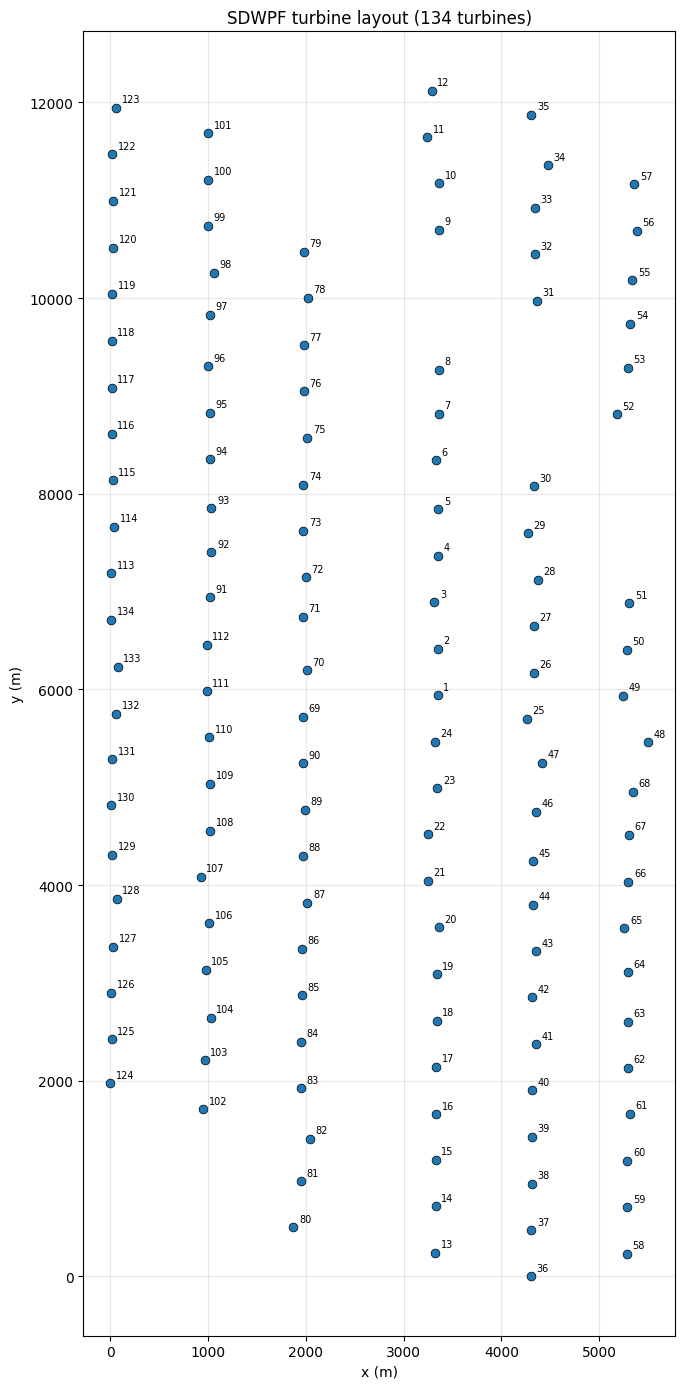

In [3]:
fig, ax = plt.subplots(figsize=(8, 14))

ax.scatter(loc["x"], loc["y"], s=40, color="tab:blue", edgecolor="black", linewidth=0.5, zorder=2)
for _, row in loc.iterrows():
    ax.annotate(
        str(int(row["TurbID"])),
        (row["x"], row["y"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7,
    )

ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title(f"SDWPF turbine layout ({len(loc)} turbines)")
ax.grid(True, alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

## 2. A smaller sub-farm of ~20 turbines

**What:** pick about 20 turbines that sit close together and train on those first.

**Why:** a 20-node graph trains in a fraction of the time of the 134-node graph, so model and graph settings can be tried quickly. Once a setup works it can be scaled back to the full farm.

**How:** choose a *seed* turbine and keep the 20 turbines nearest to it, measured by straight-line distance (the seed counts as one of the 20). This always gives a compact patch.

**Seed choice: turbine 26.** It sits halfway up the farm in the second column from the east, so its 20 nearest neighbours form a block **three columns wide** (the three eastern columns, x ≈ 3.3, 4.3, 5.3 km) and roughly seven rows tall. Three columns by seven rows means turbines are lined up both *along* the columns and *across* them. So whichever way the wind blows, many turbines have another turbine upwind of them inside the patch, which keeps upwind/downwind relationships in the small model. A single tall column would only have them when the wind blows along that column. (Notebook 02 estimates that the farm's +y axis points to compass bearing ≈ 275°, so the columns in these plots actually run roughly west–east.)

Change `SEED_TURBINE` or `N_SUBSET` below to try a different patch.

In [4]:
import numpy as np

SEED_TURBINE = 26   # centre of the patch
N_SUBSET = 20       # number of turbines to keep (seed included)

xy = loc[["x", "y"]].to_numpy()
seed_xy = loc.loc[loc["TurbID"] == SEED_TURBINE, ["x", "y"]].to_numpy()[0]

# distance from every turbine to the seed, then keep the N closest
loc["dist_to_seed"] = np.hypot(xy[:, 0] - seed_xy[0], xy[:, 1] - seed_xy[1])
subset = loc.nsmallest(N_SUBSET, "dist_to_seed").sort_values("TurbID").reset_index(drop=True)
SUBSET_IDS = subset["TurbID"].tolist()

print(f"{len(SUBSET_IDS)} turbines: {SUBSET_IDS}")
print(f"furthest turbine is {subset['dist_to_seed'].max():.0f} m from the seed")
subset

20 turbines: [1, 2, 3, 4, 23, 24, 25, 26, 27, 28, 29, 30, 46, 47, 48, 49, 50, 51, 67, 68]
furthest turbine is 1925 m from the seed


,TurbID,x,y,dist_to_seed
0,1,3349.8515,5939.23193,1005.975039
1,2,3351.0017,6416.64673,1007.680876
2,3,3314.7797,6892.18395,1243.533529
3,4,3352.0940,7366.14203,1542.542493
4,23,3346.8376,4989.86182,1536.598875
5,24,3322.2136,5465.88560,1229.328927
6,25,4260.8151,5699.75016,477.065425
7,26,4328.5300,6171.98539,0.000000
8,27,4331.9147,6650.66702,478.693596
9,28,4373.2043,7122.64010,951.703825


**What:** redraw the whole farm, with the chosen turbines highlighted in orange and the rest greyed out. Thin lines join pairs of chosen turbines that are within `RADIUS` metres of each other.

**Why:** to check by eye that the patch is compact and that the turbines are well linked. `RADIUS = 1500 m` is the neighbourhood size the project settled on in notebook 02. At 1000 m, turbines in neighbouring columns (~991 m apart, often more on the diagonal) barely connect and many nodes end up isolated.

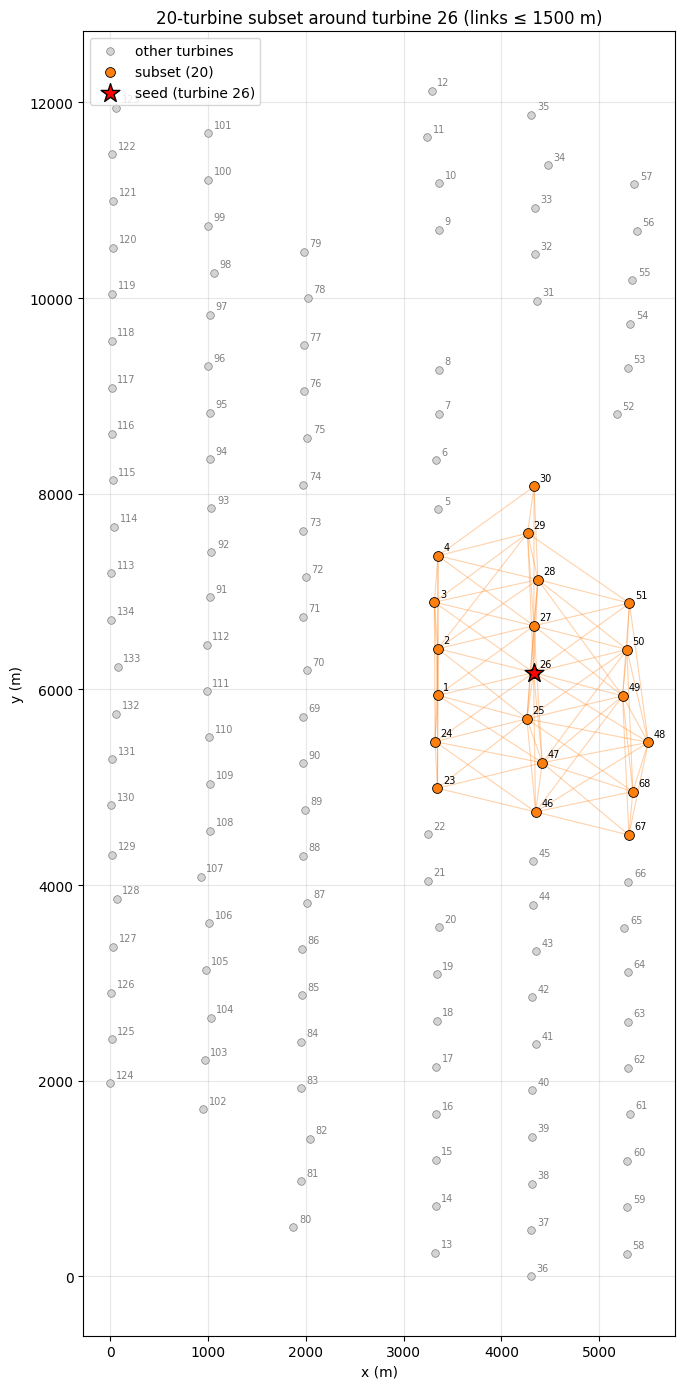

In [5]:
RADIUS = 1500  # metres; pairs closer than this are treated as neighbours

sub_xy = subset[["x", "y"]].to_numpy()
pair_dist = np.hypot(*(sub_xy[:, None, :] - sub_xy[None, :, :]).transpose(2, 0, 1))

fig, ax = plt.subplots(figsize=(8, 14))

# links between chosen turbines within RADIUS
for i in range(len(subset)):
    for j in range(i + 1, len(subset)):
        if pair_dist[i, j] <= RADIUS:
            ax.plot(sub_xy[[i, j], 0], sub_xy[[i, j], 1], color="tab:orange", alpha=0.35, lw=0.8, zorder=1)

is_sub = loc["TurbID"].isin(SUBSET_IDS)
ax.scatter(loc.loc[~is_sub, "x"], loc.loc[~is_sub, "y"], s=30, color="lightgrey", edgecolor="grey", lw=0.5, zorder=2, label="other turbines")
ax.scatter(subset["x"], subset["y"], s=50, color="tab:orange", edgecolor="black", lw=0.6, zorder=3, label=f"subset ({len(subset)})")
ax.scatter(*seed_xy, s=200, marker="*", color="red", edgecolor="black", zorder=4, label=f"seed (turbine {SEED_TURBINE})")

for _, row in loc.iterrows():
    ax.annotate(
        str(int(row["TurbID"])),
        (row["x"], row["y"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7,
        color="black" if row["TurbID"] in SUBSET_IDS else "grey",
    )

ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title(f"{len(subset)}-turbine subset around turbine {SEED_TURBINE} (links ≤ {RADIUS} m)")
ax.grid(True, alpha=0.3, zorder=0)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**What:** build the subset as a graph (turbines = nodes, an edge between every pair within `RADIUS`) and check it with `networkx`.

**Why:** before training, confirm that the patch is **one connected piece** (information can flow between any two turbines) and that **no turbine is isolated**. An isolated node gets nothing from its neighbours, so the GNN would treat it like a plain per-turbine model.

The *degree* of a turbine is how many neighbours it has. The real model will use a directed, wind-dependent graph (only upwind neighbours feed in), so these undirected counts are an upper bound.

In [6]:
import networkx as nx

G = nx.Graph()
G.add_nodes_from(SUBSET_IDS)
for i in range(len(subset)):
    for j in range(i + 1, len(subset)):
        if pair_dist[i, j] <= RADIUS:
            G.add_edge(SUBSET_IDS[i], SUBSET_IDS[j], dist=pair_dist[i, j])

degrees = dict(G.degree())
print(f"nodes:            {G.number_of_nodes()}")
print(f"edges:            {G.number_of_edges()}")
print(f"connected:        {nx.is_connected(G)}")
print(f"isolated turbines: {list(nx.isolates(G)) or 'none'}")
print(f"degree min/mean/max: {min(degrees.values())} / {np.mean(list(degrees.values())):.1f} / {max(degrees.values())}")

nodes:            20
edges:            90
connected:        True
isolated turbines: none
degree min/mean/max: 4 / 9.0 / 14


**What:** save the chosen turbine IDs to `../data/interim/ed_subset_turbines.csv`.

**Why:** later steps (data loading, windowing, training) can read this file and filter the SCADA data to just these turbines, so the selection is made in one place. `data/interim/` is gitignored, so re-run this cell to regenerate it.

In [7]:
OUT_PATH = Path("../data/interim/ed_subset_turbines.csv")
OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
subset[["TurbID", "x", "y", "dist_to_seed"]].to_csv(OUT_PATH, index=False)
print(f"saved {len(subset)} turbines to {OUT_PATH}")

saved 20 turbines to ../data/interim/ed_subset_turbines.csv


## 3. Extract the SCADA data for the 20 turbines

**What:** read the full SCADA file `wtbdata_245days.csv` (245 days of 10-minute records for all 134 turbines, ~4.7 million rows) and keep only the rows whose `TurbID` is in `SUBSET_IDS`. The result is saved as a new file `../data/wtbdata_245days_subset20.csv`.

**Why:** every later step (cleaning, windowing, training) can load this ~15× smaller file instead of the 334 MB original, which makes trying out settings much faster.

**How:** the file is read with every column as text (`dtype=str`, `keep_default_na=False`). The extract is then an exact copy of the original rows: numbers are not reformatted and the empty fields stay empty. Missing values are handled later, during cleaning, not here.

If the extract already exists (e.g. on Colab, where only the extract is uploaded), it is reused and the full file is not read.

In [8]:
SCADA_PATH = Path("../data/wtbdata_245days.csv")
SUBSET_SCADA_PATH = Path(f"../data/wtbdata_245days_subset{len(SUBSET_IDS)}.csv")

if SUBSET_SCADA_PATH.exists():
    print(f"using existing extract {SUBSET_SCADA_PATH} ({SUBSET_SCADA_PATH.stat().st_size / 1e6:.1f} MB)")
else:
    scada = pd.read_csv(SCADA_PATH, dtype=str, keep_default_na=False)
    keep = scada["TurbID"].astype(int).isin(SUBSET_IDS)
    scada_sub = scada[keep]
    scada_sub.to_csv(SUBSET_SCADA_PATH, index=False)

    print(f"full file:   {len(scada):>9,} rows, {scada['TurbID'].nunique()} turbines")
    print(f"extract:     {len(scada_sub):>9,} rows, {scada_sub['TurbID'].nunique()} turbines")
    print(f"saved to {SUBSET_SCADA_PATH} ({SUBSET_SCADA_PATH.stat().st_size / 1e6:.1f} MB)")

using existing extract ../data/wtbdata_245days_subset20.csv (49.7 MB)


**What:** sanity-check the new file.

**Why:** confirm the extract is complete before building on it. Each turbine should have the same number of rows as in the full file: 245 days × 144 ten-minute steps = 35,280. The turbine IDs should match `SUBSET_IDS` exactly.

In [9]:
check = pd.read_csv(SUBSET_SCADA_PATH)
rows_per_turbine = check.groupby("TurbID").size()

print(f"turbine IDs match subset: {sorted(rows_per_turbine.index) == sorted(SUBSET_IDS)}")
print(f"rows per turbine:         {rows_per_turbine.unique().tolist()}  (expected [{245 * 144}])")
print(f"days covered:             {check['Day'].min()} to {check['Day'].max()}")
check.head()

turbine IDs match subset: True
rows per turbine:         [35280]  (expected [35280])
days covered:             1 to 245


,TurbID,Day,Tmstamp,Wspd,Wdir,Etmp,Itmp,Ndir,Pab1,Pab2,Pab3,Prtv,Patv
0,1,1,00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1,00:10,6.17,-3.99,30.73,41.80,25.92,1.0,1.0,1.0,-0.25,494.66
2,1,1,00:20,6.27,-2.18,30.60,41.63,20.91,1.0,1.0,1.0,-0.24,509.76
3,1,1,00:30,6.42,-0.73,30.52,41.52,20.91,1.0,1.0,1.0,-0.26,542.53
4,1,1,00:40,6.25,0.89,30.49,41.38,20.91,1.0,1.0,1.0,-0.23,509.36


## 4. Pick one outage event with more than 10% of turbines missing

**What:** find a stretch of time where part of the 20-turbine patch stopped reporting while the rest kept going, and select one such event to study.

**Why:** the project's goal is to forecast turbines whose own data is missing by using their neighbours. A real partial outage is a natural first test case.

"More than 10% missing" is ambiguous, so the definitions used here are:

| Question | Choice |
|---|---|
| What counts as missing? | An **empty record**: the turbine logged nothing at that 10-min step. Readings flagged invalid by the SDWPF rules are *not* counted. |
| 10% of what? | **Turbines**: more than 2 of the 20, i.e. **3 or more** missing at the same step. |
| What is an event? | A **continuous episode** of consecutive 10-min steps that all meet the rule. |
| Farm-wide blackouts? | **Excluded**: steps where all 20 are missing do not count, because no neighbour is left to learn from. |

In this data a record is either fully present or fully empty (no rows are partly filled), so "missing" is simply "all measurement columns empty".

**What:** load the extract, mark each record as missing or not, and give every row a single time index `step` (0, 1, 2, … in 10-minute steps from day 1, 00:00). Then count the missing turbines at each step.

**Why:** `Day` + `Tmstamp` is awkward to sort and compare. One integer per time step makes it easy to find runs of consecutive steps.

In [10]:
MEASURE_COLS = ["Wspd", "Wdir", "Etmp", "Itmp", "Ndir", "Pab1", "Pab2", "Pab3", "Prtv", "Patv"]
STEPS_PER_DAY = 144  # 24 h x 6 ten-minute steps

data = pd.read_csv(SUBSET_SCADA_PATH)
data["missing"] = data[MEASURE_COLS].isna().all(axis=1)
hh, mm = data["Tmstamp"].str[:2].astype(int), data["Tmstamp"].str[3:].astype(int)
data["step"] = (data["Day"] - 1) * STEPS_PER_DAY + hh * 6 + mm // 10

per_step = data.groupby("step").agg(
    Day=("Day", "first"), Tmstamp=("Tmstamp", "first"), n_missing=("missing", "sum")
)
n_turb = len(SUBSET_IDS)
print(f"time steps: {len(per_step):,}")
print(f"steps with no turbine missing:         {(per_step['n_missing'] == 0).sum():,}")
print(f"steps with all {n_turb} missing (blackout):    {(per_step['n_missing'] == n_turb).sum():,}")
print(f"steps with >10% but not all missing:   {((per_step['n_missing'] > 0.1 * n_turb) & (per_step['n_missing'] < n_turb)).sum():,}")

time steps: 35,280
steps with no turbine missing:         33,696
steps with all 20 missing (blackout):    288
steps with >10% but not all missing:   44


**What:** group the qualifying steps (3 to 19 turbines missing) into continuous episodes and list them.

**Why:** shows every candidate event at once, so the choice is clear. Two extra columns help judge each one as a test case:
- `missing_6h_before`: missing turbine-records in the 6 hours (36 steps) *before* the event. A forecasting model needs a window of input history, so this should be low.
- `split`: which data split the day falls in (train = days 1–171, val = 172–196, test = 197–245, as set in notebook 01).

In [11]:
HISTORY_STEPS = 36  # 6 hours

per_step["in_event"] = (per_step["n_missing"] > 0.1 * n_turb) & (per_step["n_missing"] < n_turb)
# a new episode starts each time in_event switches on/off
per_step["episode"] = (per_step["in_event"] != per_step["in_event"].shift()).cumsum()

def split_of(day):
    return "train" if day <= 171 else "val" if day <= 196 else "test"

rows = []
for _, ep in per_step[per_step["in_event"]].groupby("episode"):
    s0, s1 = ep.index.min(), ep.index.max()
    before = per_step.loc[s0 - HISTORY_STEPS : s0 - 1, "n_missing"]
    rows.append({
        "Day": ep["Day"].iloc[0],
        "start": ep["Tmstamp"].iloc[0],
        "end": ep["Tmstamp"].iloc[-1],
        "steps": len(ep),
        "duration_min": len(ep) * 10,
        "min_missing": ep["n_missing"].min(),
        "max_missing": ep["n_missing"].max(),
        "missing_6h_before": int(before.sum()),
        "blackout_6h_before": bool((before == n_turb).any()),
        "split": split_of(ep["Day"].iloc[0]),
        "step_start": s0,
        "step_end": s1,
    })
episodes = pd.DataFrame(rows)
episodes

,Day,start,end,steps,duration_min,min_missing,max_missing,missing_6h_before,blackout_6h_before,split,step_start,step_end
0,65,21:20,23:10,12,120,4,18,1,False,train,9344,9355
1,67,13:20,16:30,20,200,3,15,720,True,train,9584,9603
2,201,11:10,12:50,11,110,3,19,0,False,test,28867,28877
3,201,16:50,16:50,1,10,19,19,640,True,test,28901,28901


**Choice: day 65, 21:20–23:10** (12 steps, 2 h, training split).

Each episode was examined step by step (turbines missing per 10-min step). **All four are attached to a farm-wide blackout**: in this patch, a partial outage is always the farm going down or coming back up. None stands on its own.

| Episode | Missing per step | Why / why not |
|---|---|---|
| **Day 65 (12 steps)** | 4, 6, 6, 6, 6, 15, 15, 16, 16, 16, 18, 18 → blackout | **Chosen.** Clean 6 h history (1 missing record). The first 50 min are a genuine partial outage (4–6 of 20 missing) before the farm goes down. |
| Day 67 (20 steps, longest) | 15, 14, 14, … 6, 4, 3, 3, 3 | Recovery after a blackout: the 6 h before it is mostly empty, so there is no input history. |
| Day 201, 11:10 (11 steps) | 3, 6, 19, 19, … | Clean history and in the test split, but effectively a blackout after 20 min: only turbine 47 still reports. |
| Day 201, 16:50 (1 step) | 19 | One step, with a blackout just before it. |

Because day 65 is in the **training** split, it is a case study for understanding the data, not a held-out test. Change `EVENT_DAY` / `EVENT_START` to pick another episode from the table.

In [12]:
EVENT_DAY, EVENT_START = 65, "21:20"

event = episodes[(episodes["Day"] == EVENT_DAY) & (episodes["start"] == EVENT_START)].iloc[0]
EVENT_STEPS = range(event["step_start"], event["step_end"] + 1)

ev_data = data[data["step"].isin(EVENT_STEPS)]
missing_per_turbine = ev_data.groupby("TurbID")["missing"].sum().astype(int)

print(f"event: day {event['Day']}, {event['start']}-{event['end']} "
      f"({event['steps']} steps, {event['duration_min']} min), split = {event['split']}")
print(f"turbines missing per step: {per_step.loc[EVENT_STEPS, 'n_missing'].tolist()}")
print(f"turbines missing at some point: {missing_per_turbine[missing_per_turbine > 0].index.tolist()}")
print(f"turbines never missing:         {missing_per_turbine[missing_per_turbine == 0].index.tolist()}")

event: day 65, 21:20-23:10 (12 steps, 120 min), split = train
turbines missing per step: [4, 6, 6, 6, 6, 15, 15, 16, 16, 16, 18, 18]
turbines missing at some point: [3, 4, 23, 24, 25, 26, 27, 28, 29, 30, 46, 47, 48, 49, 50, 51, 67, 68]
turbines never missing:         [1, 2]


**What:** two pictures of the event.
1. **Left, timeline:** one row per turbine, one column per 10-min step, running from 6 h before the event to 1 h after it. Red = missing. The dashed lines mark the event.
2. **Right, map:** the 20-turbine patch, with each turbine coloured by how many of the event's steps it was missing for.

**Why:** the timeline shows how the outage builds up and recovers, and that the history before it is clean. The map shows *where* the gaps are: whether the missing turbines still have reporting neighbours, which is what the GNN will rely on.

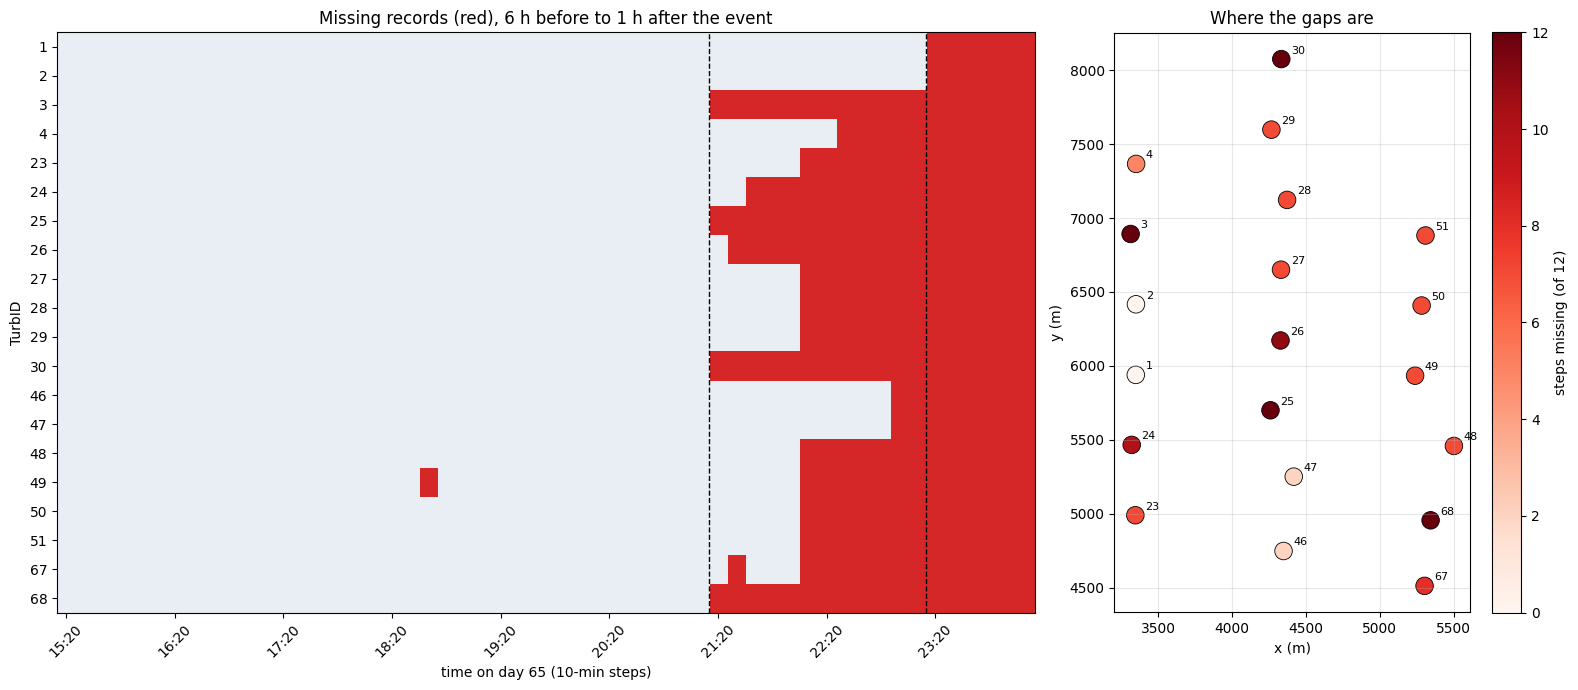

In [13]:
AFTER_STEPS = 6  # 1 hour
win = range(event["step_start"] - HISTORY_STEPS, event["step_end"] + AFTER_STEPS + 1)
grid = (
    data[data["step"].isin(win)]
    .pivot(index="TurbID", columns="step", values="missing")
    .astype(int)
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [2.2, 1]})

# timeline heatmap
ax1.imshow(grid.to_numpy(), aspect="auto", cmap=plt.matplotlib.colors.ListedColormap(["#e8eef4", "tab:red"]),
           interpolation="nearest")
ax1.set_yticks(range(len(grid)), grid.index)
tick_pos = range(0, len(grid.columns), 6)
ax1.set_xticks(tick_pos, [per_step.loc[grid.columns[i], "Tmstamp"] for i in tick_pos], rotation=45)
for s in (event["step_start"], event["step_end"] + 1):
    ax1.axvline(list(grid.columns).index(s) - 0.5, color="black", ls="--", lw=1)
ax1.set_xlabel(f"time on day {event['Day']} (10-min steps)")
ax1.set_ylabel("TurbID")
ax1.set_title("Missing records (red), 6 h before to 1 h after the event")

# map coloured by steps missing
m = subset.set_index("TurbID").join(missing_per_turbine.rename("steps_missing"))
sc = ax2.scatter(m["x"], m["y"], c=m["steps_missing"], cmap="Reds", vmin=0, vmax=event["steps"],
                 s=160, edgecolor="black", lw=0.6)
for tid, r in m.iterrows():
    ax2.annotate(f"{tid}", (r["x"], r["y"]), xytext=(7, 4), textcoords="offset points", fontsize=8)
fig.colorbar(sc, ax=ax2, label=f"steps missing (of {event['steps']})")
ax2.set_aspect("equal")
ax2.set_xlabel("x (m)")
ax2.set_ylabel("y (m)")
ax2.set_title("Where the gaps are")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Filling in the missing values with an MLP

**Goal:** during the day-65 event, estimate the **wind speed (`Wspd`)** and **power output (`Patv`)** of every turbine that stopped reporting, using the turbines that are still reporting at the same moment. Filling in missing values like this is called **imputation**.

### The idea

Turbines in this patch are close together (0.5–2 km apart), so at any moment they feel similar wind. If turbines 1 and 2 report 8 m/s, turbine 3 next to them is probably near 8 m/s too. But the relationship is not simply "copy the average". Some turbines sit in others' wakes, some produce systematically more or less, and power follows a non-linear power curve. A **multi-layer perceptron (MLP)**, a small fully connected neural network, can learn these relationships from data.

### The catch: there is no answer key for the event

The missing values during the event are, by definition, unknown. We cannot train or score the model on them. Instead:

1. **Train on complete data with values hidden on purpose.** Take time steps where all 20 turbines reported, hide a random set of turbines, and teach the MLP to reproduce the hidden values from the visible ones. Here we *do* know the answer.
2. **Test by replaying the event.** Take complete 2-hour windows from the validation and test periods, hide exactly the turbines that were missing on day 65 (same pattern, step by step), and measure how close each method gets to the real values.
3. **Apply to the real event.** Only then fill in the actual gaps on day 65.

### What the MLP sees

Each input is **one 10-minute snapshot** of the 20 turbines:

| Input (60 numbers) | Output (40 numbers) |
|---|---|
| 20 × wind speed (0 if hidden) | 20 × wind speed |
| 20 × power (0 if hidden) | 20 × power |
| 20 × mask: 1 = reporting, 0 = missing | |

The **mask** is important. Without it, the network could not tell "turbine hidden" from "turbine reporting zero wind". The output always covers all 20 turbines. For reporting turbines the answer is already in the input; for hidden ones it is the estimate we want.

This MLP deliberately ignores **where** turbines are and which way the wind blows. It only learns "turbine *i* tends to look like this when the others look like that". That makes it a baseline for the graph model later: the GNN has to beat it by using geometry and wind direction.

### 5.1 Arrange the data as time × turbine tables

**What:** reshape the long table (one row per turbine per step) into three wide tables with one row per time step and one column per turbine: wind speed, power, and a `present` flag.

**Why:** the MLP's input is a whole-patch snapshot, so each time step needs to be one row.

Negative power (turbines drawing a little from the grid when idle) is clipped to 0, following the SDWPF evaluation rules. A step is **complete** when all 20 turbines reported.

In [14]:
data["Patv_clip"] = data["Patv"].clip(lower=0)

W = data.pivot(index="step", columns="TurbID", values="Wspd")          # wind speed, m/s
P = data.pivot(index="step", columns="TurbID", values="Patv_clip")     # power, kW
PRESENT = ~data.pivot(index="step", columns="TurbID", values="missing")

w, p, present = W.to_numpy(), P.to_numpy(), PRESENT.to_numpy()
step_day = W.index.to_numpy() // STEPS_PER_DAY + 1
complete = present.all(axis=1)

print(f"table shape: {w.shape[0]:,} steps x {w.shape[1]} turbines")
print(f"complete steps: {complete.sum():,} ({complete.mean():.1%})")

table shape: 35,280 steps x 20 turbines
complete steps: 33,696 (95.5%)


### 5.2 Build the training set by hiding turbines at random

**What:** from the complete steps in the **training period (days 1–171)**:
- **Copies:** use each step `N_COPIES` = 4 times, each copy with a different random set of hidden turbines.
- **How many hidden:** anywhere from 1 to 18 of the 20 (chosen uniformly at random).
- **Scaling:** wind speed and power are standardised (subtract the mean, divide by the standard deviation, both computed on the training data). Then both are on similar scales and the network treats them equally.

**Why:**
- **Range of 1–18 hidden:** the day-65 event goes from 4 to 18 missing, so the model must cope with mild and severe outages alike. Training on the full range makes one model handle all of them.
- **Several copies:** they give the model many more examples of which turbines can be missing, from the same data.
- **Training period only:** the validation and test periods stay untouched for the evaluation in 5.4.

In [15]:
N_COPIES = 4
MAX_HIDDEN = 18
rng = np.random.default_rng(0)

train_steps = np.where(complete & (step_day <= 171))[0]
w_mu, w_sd = w[train_steps].mean(), w[train_steps].std()
p_mu, p_sd = p[train_steps].mean(), p[train_steps].std()

def make_features(ws, ps, visible):
    """Scaled wind speed and power (0 where hidden) plus the visible mask -> 60 inputs per snapshot."""
    zw = np.where(visible, (ws - w_mu) / w_sd, 0.0)
    zp = np.where(visible, (ps - p_mu) / p_sd, 0.0)
    return np.hstack([zw, zp, visible.astype(float)])

def unscale(out):
    """Network output (40 scaled numbers) -> wind speed (m/s) and power (kW), 20 each."""
    return out[:, :n_turb] * w_sd + w_mu, out[:, n_turb:] * p_sd + p_mu

rows = np.repeat(train_steps, N_COPIES)
n_hidden = rng.integers(1, MAX_HIDDEN + 1, size=len(rows))
# random order of turbines per row; the first n_hidden in that order are hidden
order = rng.random((len(rows), n_turb)).argsort(axis=1).argsort(axis=1)
visible = order >= n_hidden[:, None]

X_train = make_features(w[rows], p[rows], visible)
Y_train = np.hstack([(w[rows] - w_mu) / w_sd, (p[rows] - p_mu) / p_sd])

print(f"training examples: {len(X_train):,}  ({len(train_steps):,} complete steps x {N_COPIES} masks)")
print(f"input size {X_train.shape[1]}, output size {Y_train.shape[1]}")
print(f"scaling: wind {w_mu:.2f} ± {w_sd:.2f} m/s, power {p_mu:.0f} ± {p_sd:.0f} kW")

training examples: 93,484  (23,371 complete steps x 4 masks)
input size 60, output size 40
scaling: wind 5.53 ± 3.54 m/s, power 397 ± 450 kW


### 5.3 Train the MLP

**What:** a scikit-learn `MLPRegressor` with two hidden layers of 128 neurons each (ReLU activation, Adam optimiser).

**Why these settings:** two layers of 128 are enough to learn a non-linear mapping from 60 inputs to 40 outputs without being slow (~2 minutes on a CPU). `early_stopping=True` holds back 10% of the training examples and stops when the error on them stops improving, which guards against overfitting. Nothing has been tuned yet. This is a first working version.

scikit-learn is used because it is already installed; PyTorch would be needed for the GNN later.

In [16]:
import time

from sklearn.neural_network import MLPRegressor

mlp = MLPRegressor(
    hidden_layer_sizes=(128, 128),
    batch_size=256,
    early_stopping=True,
    max_iter=200,
    random_state=0,
)
t0 = time.time()
mlp.fit(X_train, Y_train)
print(f"trained in {time.time() - t0:.0f} s, {mlp.n_iter_} epochs, "
      f"best held-out R² = {mlp.best_validation_score_:.3f}")

trained in 162 s, 84 epochs, best held-out R² = 0.955


### 5.4 Test: replay the day-65 outage on complete data

**What:** find complete 2-hour windows (12 steps, plus 1 step before) in the **validation (days 172–196)** and **test (days 197–245)** periods. Hide exactly the day-65 pattern in each one, fill the gaps, and compare with the real values. Score = **mean absolute error (MAE)** over the hidden values only.

**Why:** this is the closest we can get to scoring the real event. Same outage shape, but at times where the true answer is known.

Two simple methods are included as **baselines**. The MLP is only worth using if it beats them:

| Method | How it fills a hidden turbine |
|---|---|
| **Patch mean** | Average of all reporting turbines at that step |
| **Last known value** | That turbine's own most recent reported value (held constant) |
| **MLP** | Network prediction from the snapshot |

Errors are also split by phase: the **partial** phase (first 5 steps, 4–6 missing) and the **severe** phase (15–18 missing).

In [17]:
EV_LEN = event["steps"]
ev_visible = present[event["step_start"] : event["step_end"] + 1]   # day-65 pattern, EV_LEN x 20
ev_hidden = ~ev_visible
severe = ev_hidden.sum(axis=1) > 0.5 * n_turb                          # steps with >half missing

def fill_patch_mean(ws, vis):
    return np.repeat(np.nanmean(np.where(vis, ws, np.nan), axis=1, keepdims=True), n_turb, axis=1)

def fill_last_known(ws, vis, before):
    out, last = np.empty_like(ws), before.copy()
    for t in range(len(ws)):
        last = np.where(vis[t], ws[t], last)
        out[t] = last
    return out

def fill_mlp(ws, ps, vis):
    return unscale(mlp.predict(make_features(ws, ps, vis)))

results = []
for split, lo, hi in [("val", 172, 196), ("test", 197, 245)]:
    starts = [s for s in range(1, len(w) - EV_LEN)
              if lo <= step_day[s] <= hi and complete[s - 1 : s + EV_LEN].all()][::EV_LEN]  # non-overlapping
    for s in starts:
        ws, ps = w[s : s + EV_LEN], p[s : s + EV_LEN]
        mlp_w, mlp_p = fill_mlp(ws, ps, ev_visible)
        fills = {
            "patch mean": (fill_patch_mean(ws, ev_visible), fill_patch_mean(ps, ev_visible)),
            "last known value": (fill_last_known(ws, ev_visible, w[s - 1]), fill_last_known(ps, ev_visible, p[s - 1])),
            "MLP": (mlp_w, mlp_p),
        }
        for method, (fw, fp) in fills.items():
            for phase, rows_sel in [("partial", ~severe), ("severe", severe), ("all", slice(None))]:
                h = ev_hidden[rows_sel]
                results.append({
                    "split": split, "method": method, "phase": phase,
                    "wspd_abs_err": np.abs(fw - ws)[rows_sel][h].mean(),
                    "patv_abs_err": np.abs(fp - ps)[rows_sel][h].mean(),
                    "n": h.sum(),
                })
    print(f"{split}: {len(starts)} replayed windows")

res = pd.DataFrame(results)
# weight each window by its number of hidden values -> MAE over all hidden values
res["w_err"], res["p_err"] = res["wspd_abs_err"] * res["n"], res["patv_abs_err"] * res["n"]
g = res.groupby(["split", "phase", "method"], sort=False)[["w_err", "p_err", "n"]].sum()
mae = pd.DataFrame({"Wspd MAE (m/s)": g["w_err"] / g["n"], "Patv MAE (kW)": g["p_err"] / g["n"]}).round(
    {"Wspd MAE (m/s)": 3, "Patv MAE (kW)": 1})
mae.unstack("split")

val: 234 replayed windows
test: 465 replayed windows


Wspd MAE (m/s)        Patv MAE (kW)      
split                               val   test           val  test
phase   method                                                    
partial patch mean                0.535  0.533          79.2  77.8
        last known value          0.612  0.605          79.3  67.2
        MLP                       0.477  0.466          69.8  65.6
severe  patch mean                0.615  0.609         101.1  82.9
        last known value          0.889  0.837         110.1  96.4
        MLP                       0.603  0.585          84.9  82.7
all     patch mean                0.599  0.594          96.8  81.9
        last known value          0.834  0.791         104.0  90.7
        MLP                       0.578  0.562          81.9  79.4

### 5.5 Fill the real day-65 gaps

**What:** run the trained MLP on the actual event snapshots and write its estimates into the gaps.

**Why:** this is the end product: a complete wind-speed and power record for the event.

There is no truth to compare against here, so the plot is a plausibility check. Do the filled values join smoothly onto each turbine's history before it dropped out, and do they move with the turbines that are still reporting? Three turbines are shown:
- **turbine 3:** missing for the whole event
- **turbine 47:** drops out late
- **turbine 1:** reports throughout and serves as a reference

filled 142 missing turbine-steps; saved to ../data/interim/event_day65_filled_mlp.csv


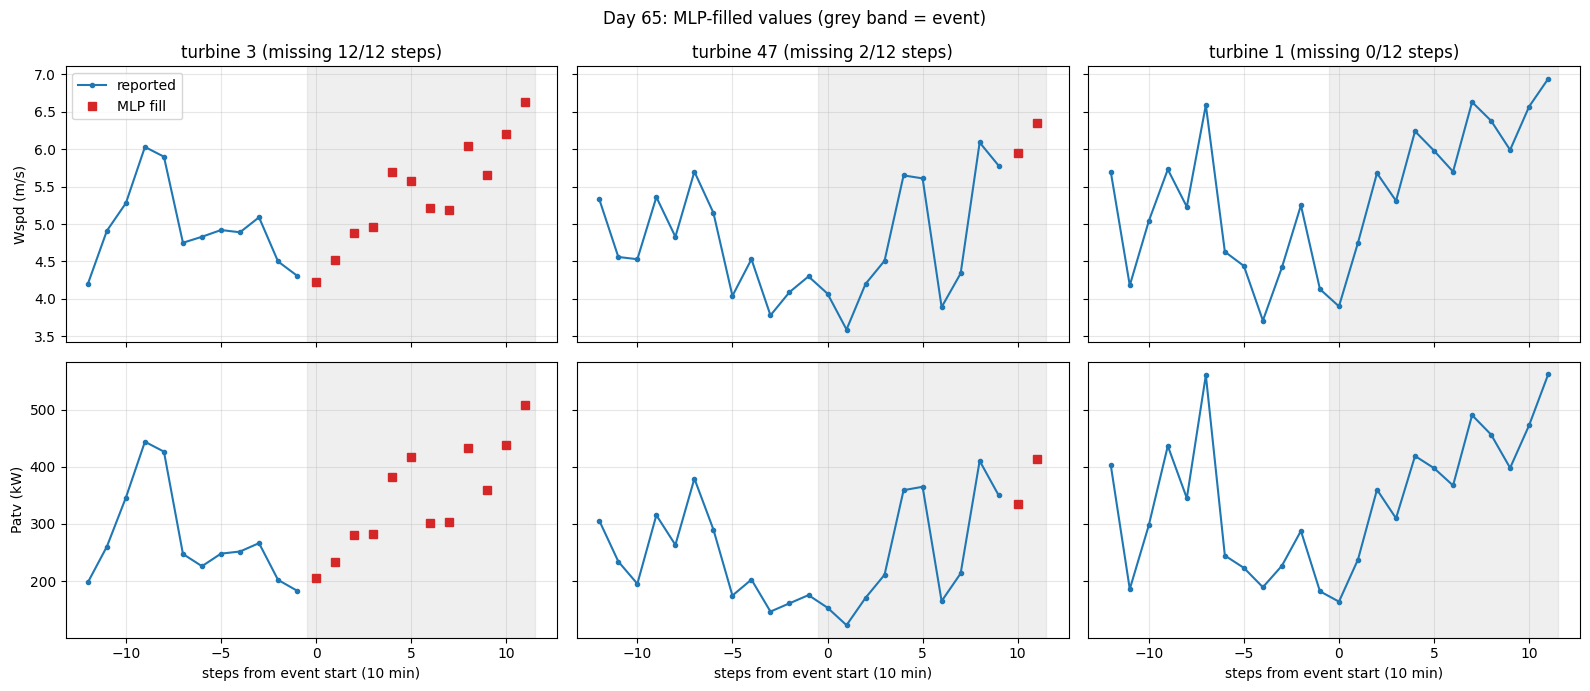

In [18]:
ev_steps = np.arange(event["step_start"], event["step_end"] + 1)
fill_w, fill_p = fill_mlp(w[ev_steps], p[ev_steps], ev_visible)

filled_w = np.where(ev_visible, w[ev_steps], fill_w)
filled_p = np.where(ev_visible, p[ev_steps], fill_p)

event_filled = pd.DataFrame({
    "step": np.repeat(ev_steps, n_turb),
    "Tmstamp": np.repeat(per_step.loc[ev_steps, "Tmstamp"].to_numpy(), n_turb),
    "TurbID": np.tile(W.columns.to_numpy(), len(ev_steps)),
    "Wspd": filled_w.ravel(),
    "Patv": filled_p.ravel(),
    "imputed": ev_hidden.ravel(),
})
FILLED_PATH = Path(f"../data/interim/event_day{event['Day']}_filled_mlp.csv")
event_filled.to_csv(FILLED_PATH, index=False)
print(f"filled {ev_hidden.sum()} missing turbine-steps; saved to {FILLED_PATH}")

SHOW = [3, 47, 1]
hist = np.arange(event["step_start"] - 12, event["step_end"] + 1)   # 2 h before + event
fig, axes = plt.subplots(2, len(SHOW), figsize=(16, 7), sharex=True, sharey="row")
for col, tid in enumerate(SHOW):
    j = W.columns.get_loc(tid)
    for row, (obs, fill, label) in enumerate([(w, fill_w, "Wspd (m/s)"), (p, fill_p, "Patv (kW)")]):
        ax = axes[row, col]
        ax.plot(hist - event["step_start"], obs[hist, j], "o-", ms=3, color="tab:blue", label="reported")
        hid = ev_hidden[:, j]
        ax.plot((ev_steps - event["step_start"])[hid], fill[hid, j], "s", ms=6, color="tab:red", label="MLP fill")
        ax.axvspan(-0.5, EV_LEN - 0.5, color="grey", alpha=0.12)
        ax.set_ylabel(label if col == 0 else "")
        if row == 0:
            ax.set_title(f"turbine {tid} (missing {hid.sum()}/{EV_LEN} steps)")
        if row == 1:
            ax.set_xlabel("steps from event start (10 min)")
        ax.grid(alpha=0.3)
axes[0, 0].legend()
fig.suptitle(f"Day {event['Day']}: MLP-filled values (grey band = event)")
plt.tight_layout()
plt.show()

### 5.6 Takeaways

- **The MLP beats both baselines in every phase**, on both validation and test. Overall on the test windows: 0.56 m/s wind-speed error vs 0.59 (patch mean) and 0.79 (last known value). Power error is 79 kW vs 82 and 91 kW. For scale, the farm's average output is ~400 kW.
- **The gain is largest in the partial phase** (4–6 missing): 11–13% lower wind-speed error than the patch mean. With many neighbours still reporting, the MLP can use turbine-specific relationships.
- **In the severe phase (15–18 missing) the MLP is barely better than the patch mean.** With only 2–5 turbines left there is little to work with, and every method converges to "roughly what the survivors see".
- **"Last known value" falls behind as the gap gets longer.** It cannot follow the wind once a turbine has been missing for a while.
- **On the real event** the filled values join the turbines' own history and follow the rising wind seen by the reporting turbines.

**Limitations of this first model:**
- Each snapshot is handled on its own. The model does not use the turbine's own history before it dropped out, nor how the wind was trending.
- It does not know turbine positions or wind direction, so it cannot tell which neighbours are upwind.
- It has not been tuned at all (size, number of masks, learning rate).

These are exactly what the next models would add: a short time window of inputs, and then the wind-following graph (GNN).

## 6. Filling in the missing values with a Transformer

**Goal:** the same task as Section 5. Estimate `Wspd` and `Patv` for the missing turbines from the reporting ones at the same moment, but with a **Transformer** instead of an MLP. Training data, test procedure and baselines are identical, so the two models can be compared directly.

### What a Transformer does differently

The MLP squashes all 60 inputs into one long vector and mixes everything with everything through fixed weights. A Transformer instead keeps **one token per turbine** (20 tokens) and lets the tokens exchange information through **attention**:

1. Each token asks a question (*query*): "what do I need to know?"
2. Each token advertises what it has (*key*): "here is what I know".
3. Each turbine compares its query with every other turbine's key, turns the scores into weights that add up to 1, and takes a weighted average of their information (*values*).

So a missing turbine can **decide, case by case, which reporting turbines to listen to**. With 15 turbines missing it has to use whoever is left. The MLP has to learn separate fixed weights for every possible combination of missing turbines, while attention handles any combination naturally. As a bonus, the attention weights can be **plotted**, showing which neighbours the model relied on.

### Design choices

| Choice | What | Why |
|---|---|---|
| **Tokens** | 20 turbines, one 10-min snapshot | Same information as the MLP: a like-for-like comparison |
| **Token content** | scaled wind speed, scaled power (0 if hidden), mask flag | Same as the MLP's inputs, arranged per turbine |
| **Turbine identity** | learned turbine embedding **+** `(x, y)` position | Attention treats tokens as an unordered set. Without these the model could not tell turbine 3 from turbine 47. The embedding captures turbine-specific quirks; the coordinates let it reason about distance. |
| **Who can be attended to** | only **reporting** turbines | Hidden tokens carry no measurements, so they are blocked as keys (`key_padding_mask`). This also makes the attention maps easy to read: weights show which *reporting* turbines were used. |
| **Loss** | error on **hidden** turbines only | The answer for reporting turbines is already in the input. Scoring only the hidden ones focuses all learning on the real task (the same trick BERT uses for masked words). |

### 6.1 Turn the training data into tokens

**What:** reuse exactly the same training examples as the MLP (same complete steps, same 4 random masks per step from 5.2). Rearrange each one from a flat vector of 60 numbers into a **20 × 3** array (turbine × [wind, power, mask]). Turbine coordinates are centred and converted to km.

**Why:** identical data means any difference in results comes from the model, not from the data. Kilometres keep the coordinates on a similar scale to the other inputs (roughly −2 to +2).

**Device:** `DEVICE` is the GPU when one is available (e.g. a Colab GPU runtime) and the CPU otherwise. Models and tensors are created on `DEVICE`, and outputs are moved back with `.cpu()` before NumPy or plotting. Results on a GPU can differ very slightly from CPU runs because the GPU uses different numerical kernels.

In [19]:
import torch
from torch import nn

torch.manual_seed(0)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # GPU on Colab, CPU otherwise
print(f"device: {DEVICE}" + (f" ({torch.cuda.get_device_name()})" if DEVICE.type == "cuda" else ""))

def make_tokens(ws, ps, visible):
    """(..., 20) arrays -> (..., 20, 3) tokens: scaled wind, scaled power (0 where hidden), visible flag."""
    zw = np.where(visible, (ws - w_mu) / w_sd, 0.0)
    zp = np.where(visible, (ps - p_mu) / p_sd, 0.0)
    return np.stack([zw, zp, visible.astype(float)], axis=-1).astype(np.float32)

X_tok = torch.tensor(make_tokens(w[rows], p[rows], visible), device=DEVICE)
Y_tok = torch.tensor(np.stack([(w[rows] - w_mu) / w_sd, (p[rows] - p_mu) / p_sd], axis=-1).astype(np.float32), device=DEVICE)

turb_xy = subset.set_index("TurbID").loc[W.columns, ["x", "y"]].to_numpy()
turb_xy_km = (turb_xy - turb_xy.mean(axis=0)) / 1000.0

print(f"tokens: {tuple(X_tok.shape)}  (examples x turbines x features)")
print(f"targets: {tuple(Y_tok.shape)}  (examples x turbines x [wind, power])")

device: cpu
tokens: (93484, 20, 3)  (examples x turbines x features)
targets: (93484, 20, 2)  (examples x turbines x [wind, power])


### 6.2 Define the model

**What:** a small Transformer encoder:

1. **Embed:** each turbine's 3 inputs → a 64-number vector, plus its turbine embedding, plus a projection of its `(x, y)`.
2. **3 attention blocks.** In each, every turbine attends to the reporting turbines (4 attention *heads*, i.e. 4 different "questions" in parallel), then passes through a small feed-forward layer. Residual connections and layer normalisation keep training stable.
3. **Read out:** each turbine's final vector → 2 numbers (wind speed, power).

**Why this size:** 64-wide, 3 layers is small (~100k parameters) and trains on a CPU in about 25 minutes (~50–90 s per epoch, at most 20 epochs). That is much slower than the MLP: each example is 20 tokens that all attend to each other. The attention block is written out by hand instead of using PyTorch's built-in `TransformerEncoder` so that the attention weights can be stored and plotted in 6.6.

In [20]:
class AttentionBlock(nn.Module):
    """Pre-norm Transformer block that keeps its last attention weights for inspection."""

    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))
        self.drop = nn.Dropout(dropout)
        self.last_attn = None  # (batch, query turbine, key turbine), averaged over heads

    def forward(self, h, hidden):
        z = self.norm1(h)
        a, self.last_attn = self.attn(z, z, z, key_padding_mask=hidden, need_weights=True)
        h = h + self.drop(a)
        return h + self.drop(self.ff(self.norm2(h)))


class ImputationTransformer(nn.Module):
    def __init__(self, turb_xy_km, d_model=64, n_heads=4, n_layers=3, d_ff=128, dropout=0.1):
        super().__init__()
        n = len(turb_xy_km)
        self.embed_input = nn.Linear(3, d_model)
        self.embed_turbine = nn.Embedding(n, d_model)
        self.embed_position = nn.Linear(2, d_model)
        self.register_buffer("xy", torch.tensor(turb_xy_km, dtype=torch.float32))
        self.blocks = nn.ModuleList(AttentionBlock(d_model, n_heads, d_ff, dropout) for _ in range(n_layers))
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, 2)

    def forward(self, tokens):
        hidden = tokens[..., 2] < 0.5
        h = self.embed_input(tokens) + self.embed_turbine.weight + self.embed_position(self.xy)
        for block in self.blocks:
            h = block(h, hidden)
        return self.head(self.norm(h))


transformer = ImputationTransformer(turb_xy_km).to(DEVICE)
print(f"parameters: {sum(t.numel() for t in transformer.parameters()):,}")

parameters: 102,402


### 6.3 Train

**What:**
- **Hold-out:** set aside 10% of the training examples (as the MLP's `early_stopping` did).
- **Training:** mini-batches of 256 with the AdamW optimiser.
- **Each epoch:** score the hold-out on the hidden-turbine error.
- **Stopping:** stop when the hold-out error has not improved for 5 epochs, or after 20 epochs, and keep the best weights. In a trial run, gains after ~15 epochs were tiny.

**Why:** this is the same early-stopping logic the MLP used, written out by hand because PyTorch does not provide a ready-made training loop. The loss curve shows whether training has settled.

trained in 1309 s, 18 epochs, best hold-out MSE (scaled) = 0.0764


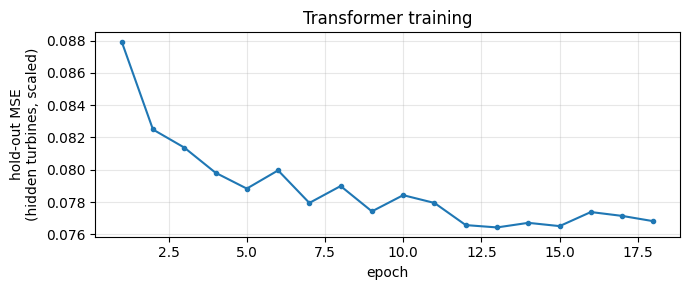

In [21]:
def hidden_mse(pred, target, tokens):
    hidden = tokens[..., 2] < 0.5
    return ((pred - target) ** 2)[hidden].mean()

BATCH, MAX_EPOCHS, PATIENCE = 256, 20, 5
perm = torch.randperm(len(X_tok), generator=torch.Generator().manual_seed(0))
n_hold = len(X_tok) // 10
hold_idx, fit_idx = perm[:n_hold], perm[n_hold:]

optimizer = torch.optim.AdamW(transformer.parameters(), lr=1e-3, weight_decay=1e-4)
history, best_loss, best_state, bad_epochs = [], float("inf"), None, 0
t0 = time.time()
for epoch in range(MAX_EPOCHS):
    transformer.train()
    shuffled = fit_idx[torch.randperm(len(fit_idx))]
    for i in range(0, len(shuffled), BATCH):
        b = shuffled[i : i + BATCH]
        optimizer.zero_grad()
        hidden_mse(transformer(X_tok[b]), Y_tok[b], X_tok[b]).backward()
        optimizer.step()

    transformer.eval()
    with torch.no_grad():
        hold_loss = hidden_mse(transformer(X_tok[hold_idx]), Y_tok[hold_idx], X_tok[hold_idx]).item()
    history.append(hold_loss)
    if hold_loss < best_loss - 1e-4:
        best_loss, bad_epochs = hold_loss, 0
        best_state = {k: v.clone() for k, v in transformer.state_dict().items()}
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            break

transformer.load_state_dict(best_state)
transformer.eval()
print(f"trained in {time.time() - t0:.0f} s, {len(history)} epochs, best hold-out MSE (scaled) = {best_loss:.4f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(1, len(history) + 1), history, "o-", ms=3)
ax.set_xlabel("epoch")
ax.set_ylabel("hold-out MSE\n(hidden turbines, scaled)")
ax.set_title("Transformer training")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6.4 Test: replay the day-65 outage, compared with the MLP

**What:** exactly the procedure from 5.4. Use the same complete 2-hour windows in the validation and test periods, hide the same day-65 pattern, and score the MAE on hidden values only. The Transformer's rows are added to the Section 5 table.

**Why:** same windows, same pattern, same metric. The only thing that changes is the model.

In [22]:
def fill_transformer(ws, ps, vis):
    with torch.no_grad():
        out = transformer(torch.tensor(make_tokens(ws, ps, vis), device=DEVICE)).cpu().numpy()
    return out[..., 0] * w_sd + w_mu, out[..., 1] * p_sd + p_mu

tf_results = []
for split, lo, hi in [("val", 172, 196), ("test", 197, 245)]:
    starts = [s for s in range(1, len(w) - EV_LEN)
              if lo <= step_day[s] <= hi and complete[s - 1 : s + EV_LEN].all()][::EV_LEN]
    for s in starts:
        ws, ps = w[s : s + EV_LEN], p[s : s + EV_LEN]
        fw, fp = fill_transformer(ws, ps, ev_visible)
        for phase, rows_sel in [("partial", ~severe), ("severe", severe), ("all", slice(None))]:
            h = ev_hidden[rows_sel]
            tf_results.append({
                "split": split, "method": "Transformer", "phase": phase,
                "w_err": np.abs(fw - ws)[rows_sel][h].sum(),
                "p_err": np.abs(fp - ps)[rows_sel][h].sum(),
                "n": h.sum(),
            })

g_tf = pd.DataFrame(tf_results).groupby(["split", "phase", "method"], sort=False)[["w_err", "p_err", "n"]].sum()
mae_tf = pd.DataFrame({"Wspd MAE (m/s)": g_tf["w_err"] / g_tf["n"], "Patv MAE (kW)": g_tf["p_err"] / g_tf["n"]}).round(
    {"Wspd MAE (m/s)": 3, "Patv MAE (kW)": 1})

comparison = pd.concat([mae, mae_tf]).sort_index(level=["split", "phase"], sort_remaining=False)
comparison = comparison.unstack("split").reindex(
    pd.MultiIndex.from_product([["partial", "severe", "all"],
                                ["patch mean", "last known value", "MLP", "Transformer"]],
                               names=["phase", "method"]))
comparison

Wspd MAE (m/s)        Patv MAE (kW)       
split                              test    val          test    val
phase   method                                                     
partial patch mean                0.533  0.535          77.8   79.2
        last known value          0.605  0.612          67.2   79.3
        MLP                       0.466  0.477          65.6   69.8
        Transformer               0.435  0.422          55.3   56.8
severe  patch mean                0.609  0.615          82.9  101.1
        last known value          0.837  0.889          96.4  110.1
        MLP                       0.585  0.603          82.7   84.9
        Transformer               0.552  0.553          72.0   73.1
all     patch mean                0.594  0.599          81.9   96.8
        last known value          0.791  0.834          90.7  104.0
        MLP                       0.562  0.578          79.4   81.9
        Transformer               0.529  0.527          68.7   69.9

### 6.5 Fill the real day-65 gaps: Transformer vs MLP

**What:** run the Transformer on the real event and plot its fills next to the MLP's for the same turbines as in 5.5. The filled event is saved alongside the MLP version.

**Why:** if the two models broadly agree, that is reassuring. Where they disagree, the replay scores in 6.4 say which to trust more.

saved to ../data/interim/event_day65_filled_transformer.csv


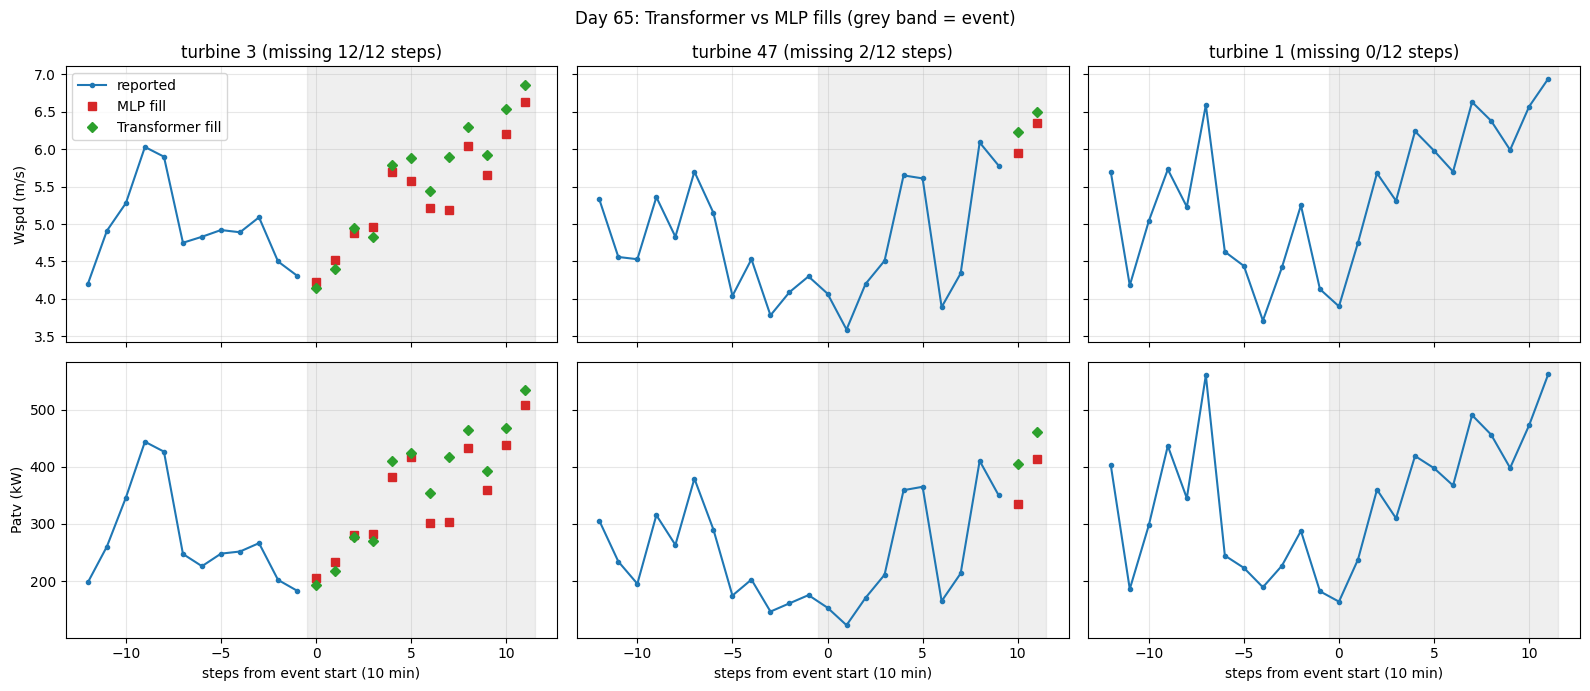

In [23]:
tf_w, tf_p = fill_transformer(w[ev_steps], p[ev_steps], ev_visible)

event_filled_tf = event_filled.copy()
event_filled_tf["Wspd"] = np.where(ev_visible, w[ev_steps], tf_w).ravel()
event_filled_tf["Patv"] = np.where(ev_visible, p[ev_steps], tf_p).ravel()
FILLED_TF_PATH = Path(f"../data/interim/event_day{event['Day']}_filled_transformer.csv")
event_filled_tf.to_csv(FILLED_TF_PATH, index=False)
print(f"saved to {FILLED_TF_PATH}")

fig, axes = plt.subplots(2, len(SHOW), figsize=(16, 7), sharex=True, sharey="row")
for col, tid in enumerate(SHOW):
    j = W.columns.get_loc(tid)
    hid = ev_hidden[:, j]
    x_ev = (ev_steps - event["step_start"])[hid]
    for row, (obs, f_mlp, f_tf, label) in enumerate([(w, fill_w, tf_w, "Wspd (m/s)"), (p, fill_p, tf_p, "Patv (kW)")]):
        ax = axes[row, col]
        ax.plot(hist - event["step_start"], obs[hist, j], "o-", ms=3, color="tab:blue", label="reported")
        ax.plot(x_ev, f_mlp[hid, j], "s", ms=6, color="tab:red", label="MLP fill")
        ax.plot(x_ev, f_tf[hid, j], "D", ms=5, color="tab:green", label="Transformer fill")
        ax.axvspan(-0.5, EV_LEN - 0.5, color="grey", alpha=0.12)
        ax.set_ylabel(label if col == 0 else "")
        if row == 0:
            ax.set_title(f"turbine {tid} (missing {hid.sum()}/{EV_LEN} steps)")
        if row == 1:
            ax.set_xlabel("steps from event start (10 min)")
        ax.grid(alpha=0.3)
axes[0, 0].legend()
fig.suptitle(f"Day {event['Day']}: Transformer vs MLP fills (grey band = event)")
plt.tight_layout()
plt.show()

### 6.6 Which neighbours did the Transformer listen to?

**What:** read the attention weights from the **last** attention block. They are averaged over the 4 heads, and for each missing turbine they add up to 1 across the reporting turbines.

- **Left and middle, maps:** for turbine 3 (missing all event), arrows from each reporting turbine, thicker and darker = more attention. Shown at the first event step (4 missing, many to choose from) and at step 5 (15 missing, few left).
- **Right, attention vs distance:** across all replayed test windows, the average attention a hidden turbine gives a reporting one, against the distance between them.

**Why:** the model was given coordinates but never told that near turbines matter more. If attention falls with distance, it learned that geometry on its own. That is a sign it is using sensible information, and the effect a graph model would build in explicitly.

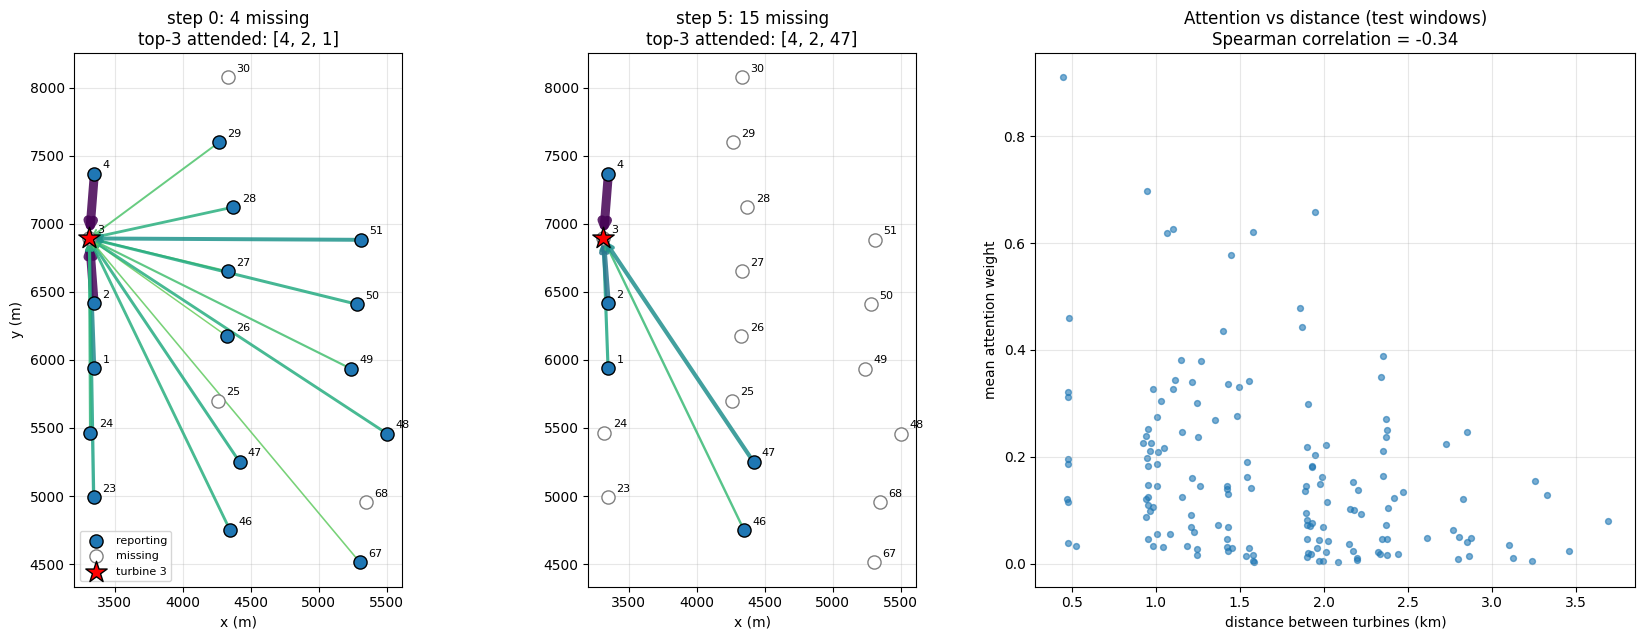

In [24]:
def last_attention(ws, ps, vis):
    with torch.no_grad():
        transformer(torch.tensor(make_tokens(ws, ps, vis), device=DEVICE))
    return transformer.blocks[-1].last_attn.cpu().numpy()   # (steps, query, key)

ev_attn = last_attention(w[ev_steps], p[ev_steps], ev_visible)
FOCUS = 3
jf = W.columns.get_loc(FOCUS)

fig, axes = plt.subplots(1, 3, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for ax, t in zip(axes[:2], [0, 5]):
    a = ev_attn[t, jf]
    for k in np.where(ev_visible[t])[0]:
        ax.annotate("", xy=turb_xy[jf], xytext=turb_xy[k],
                    arrowprops=dict(arrowstyle="->", color=plt.cm.viridis_r(0.15 + 0.85 * a[k] / a.max()),
                                    lw=0.5 + 6 * a[k] / a.max(), alpha=0.85))
    ax.scatter(*turb_xy[ev_visible[t]].T, s=90, color="tab:blue", edgecolor="black", zorder=3, label="reporting")
    ax.scatter(*turb_xy[~ev_visible[t]].T, s=90, color="white", edgecolor="grey", zorder=3, label="missing")
    ax.scatter(*turb_xy[jf], s=260, marker="*", color="red", edgecolor="black", zorder=4, label=f"turbine {FOCUS}")
    for k, tid in enumerate(W.columns):
        ax.annotate(str(tid), turb_xy[k], xytext=(6, 4), textcoords="offset points", fontsize=8)
    top = W.columns[np.argsort(a)[::-1][:3]].tolist()
    ax.set_title(f"step {t}: {(~ev_visible[t]).sum()} missing\ntop-3 attended: {top}")
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("y (m)")
axes[0].legend(loc="lower left", fontsize=8)

# attention vs distance across replayed test windows
dist_km = np.hypot(*(turb_xy[:, None, :] - turb_xy[None, :, :]).transpose(2, 0, 1)) / 1000
att_sum, att_cnt = np.zeros((n_turb, n_turb)), np.zeros((n_turb, n_turb))
test_starts = [s for s in range(1, len(w) - EV_LEN)
               if 197 <= step_day[s] <= 245 and complete[s - 1 : s + EV_LEN].all()][::EV_LEN]
for s in test_starts:
    A = last_attention(w[s : s + EV_LEN], p[s : s + EV_LEN], ev_visible)
    pair = ev_hidden[:, :, None] & ev_visible[:, None, :]       # hidden query -> reporting key
    att_sum += np.where(pair, A, 0).sum(axis=0)
    att_cnt += pair.sum(axis=0)
ok = att_cnt > 0
mean_att = att_sum[ok] / att_cnt[ok]
axes[2].scatter(dist_km[ok], mean_att, s=18, alpha=0.6)
rho = pd.Series(dist_km[ok]).corr(pd.Series(mean_att), method="spearman")
axes[2].set_xlabel("distance between turbines (km)")
axes[2].set_ylabel("mean attention weight")
axes[2].set_title(f"Attention vs distance (test windows)\nSpearman correlation = {rho:.2f}")
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6.7 Takeaways

- **The Transformer beats the MLP in every phase, on both validation and test.** Overall on the test windows: 0.53 m/s wind-speed error vs 0.56 (MLP), and **69 kW vs 79 kW power error (13% lower)**.
- **The biggest gain is power in the partial phase** (4–6 missing): 55 kW vs 66 kW on test, 57 vs 70 on validation. With many turbines to choose from, attention can pick the most informative ones for each missing turbine.
- **It also helps in the severe phase** (15–18 missing): 72 kW vs 83 kW. There the MLP was barely better than the patch mean.
- **The attention maps make sense.** Turbine 3 relies mostly on turbines 4 and 2, its direct neighbours in the same column (~474 m away), whether 4 or 15 turbines are missing.
- **Attention falls with distance, but only moderately** (Spearman −0.34). The model learned on its own that near turbines matter more, but distance is far from the whole story; the wide scatter suggests other factors, such as wind direction, also matter. The wind-following graph model will build that in explicitly.
- **The cost is training time:** about 25 minutes on a CPU against about 1 minute for the MLP.

**Limitations** are the same as for the MLP: one snapshot at a time, no wind direction, no tuning.

## 7. Filling in the missing values with a wind-following GNN

### Hypothesis

> A model that passes information **only from upwind turbines to downwind turbines** produces more accurate fills than one that ignores the wind.

**Why it might hold:** wind reaches the upwind turbine first. Its wind speed and power are an early, direct view of the air that is about to hit the downwind turbine, including the wake (slower, more turbulent air) the upwind turbine leaves behind. Turbines side by side or downwind see different air.

### What a GNN is, compared with Section 6

A **graph neural network (GNN)** treats turbines as **nodes** and lets information flow only along **edges**. In each layer, a node collects messages from the nodes that point to it and updates itself. The model used here, **GATv2** (graph attention), does this with attention, exactly like the Transformer, with one difference:

- **Transformer:** every turbine may attend to *every* reporting turbine (a complete graph).
- **GATv2:** a turbine may only attend to the turbines that have an **edge** into it.

So the graph is a **rule about who may listen to whom**, and the hypothesis is a claim about which rule works best.

### The test: same model, three graphs

The GNN is trained three times. **Everything is identical except the edges**:

| Graph | Edge A → B exists when… | Role |
|---|---|---|
| **Wind (upwind → downwind)** | B is downwind of A: within 1500 m and within ±45° of the wind direction | the hypothesis |
| **Reversed (downwind → upwind)** | the same pairs, arrows flipped | control: same neighbours, wrong direction |
| **Distance** | A and B are within 1500 m, any direction | control: ignores the wind |

The 1500 m / 45° settings and the farm orientation (`ALPHA` = 275°) are the ones chosen in notebook 02.

**What would support the hypothesis:** *Wind* beats *Reversed* (the direction matters, not just which turbines are paired) **and** *Wind* beats *Distance* (restricting to upwind helps rather than hurts).

**Fallback rule:** if a missing turbine has **no reporting turbine** pointing into it, one edge is added from the **nearest reporting turbine**. This applies to all three graphs alike. Because it mixes in a little of the distance graph, the results are also reported separately for missing values that *did* have a reporting upwind neighbour.

**A caution from notebook 02:** the wake signal at this farm is weak (a few kW against a ~450 kW mean). The farm's orientation is known only up to a 180° ambiguity (275° vs 95°). The *Reversed* graph is exactly the 95° alternative, so this experiment is also a test of that open question.

### 7.1 Wind direction for every time step

**What:** estimate one wind direction per 10-minute step for the whole farm, using the project's own `windgnn` package, with the same method as notebook 01:
- **Per turbine:** the absolute direction is nacelle direction + relative wind direction (`Ndir + Wdir`).
- **Calibration:** each turbine's constant bias is learned on the **training days only**.
- **Combining:** at each step, the farm direction is the average over all valid turbines with wind ≥ 4 m/s.

**Why all 134 turbines, not just the 20?**
- **Consistency:** `ALPHA` = 275° was estimated relative to this full-farm direction, so the edges only point the right way if the direction is computed the same way.
- **Coverage during outages:** when most of the patch is offline, turbines elsewhere in the farm still report the wind direction.

Steps without an estimate (light wind, or nothing reporting) take the **most recent** estimate. The wind direction changes slowly, so this is a reasonable fill. The result is cached in `data/interim/`.

In [25]:
import sys

ROOT = Path.cwd()
while not (ROOT / "src" / "windgnn").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from windgnn import config as C
from windgnn import data as D
from windgnn import graphs as G

ALPHA, CONE_DEG, RADIUS_M = 275.0, 45.0, 1500.0   # notebook 02 primary configuration

FARM_DIR_PATH = Path("../data/interim/ed_farm_wind_direction.csv")
if FARM_DIR_PATH.exists():
    farm = pd.read_csv(FARM_DIR_PATH, index_col=0)
else:
    full = D.clean(D.load_scada(path=SCADA_PATH))
    lo, hi = C.SPLIT_DAYS["train"]
    _, yaw_offsets = D.estimate_farm_wind_direction(full[(full.Day >= lo) & (full.Day <= hi)])
    farm, _ = D.estimate_farm_wind_direction(full, offsets=yaw_offsets)
    farm.to_csv(FARM_DIR_PATH)
    del full

# farm index t matches our step index (both start at day 1, 00:00)
wind_from = farm["farm_dir"].reindex(W.index).ffill().bfill().to_numpy()
has_est = W.index.isin(farm.index)
print(f"steps with a direct estimate: {has_est.sum():,} of {len(W):,} ({has_est.mean():.0%}); "
      f"the rest are carried forward")
print(f"during the event, wind from: {np.round(wind_from[ev_steps]).astype(int).tolist()} deg")
print(f"turbines farm-wide giving a direction during the event: "
      f"{farm['n_turbines'].reindex(ev_steps).astype('Int64').tolist()}")

steps with a direct estimate: 26,610 of 35,280 (75%); the rest are carried forward
during the event, wind from: [41, 42, 38, 33, 32, 28, 23, 22, 17, 17, 9, 8] deg
turbines farm-wide giving a direction during the event: [67, 58, 64, 72, 72, 69, 55, 38, 45, 53, 38, 32]


### 7.2 Build the three graphs for every time step

**What:** for every time step and every ordered pair of turbines (A, B), check whether B is downwind of A. The pair's direction must be within ±45° of the wind's flow direction and the distance at most 1500 m. This gives a 20 × 20 yes/no table per step (`A_wind[t, a, b]` = edge a → b).

- **Reversed** is the same table transposed (every arrow flipped).
- **Distance** is one fixed table: every pair within 1500 m, both ways.

**Why:** computing all steps at once with NumPy is fast. A check confirms that the result matches the package's own `edges_for_direction` from notebook 02.

The **in-degree** of a turbine is how many turbines point into it, i.e. how many neighbours it can listen to. **Front-row** turbines are those with no upwind neighbour inside the patch at that moment.

In [26]:
offset = turb_xy[None, :, :] - turb_xy[:, None, :]          # offset[a, b] = position of b relative to a
pair_dist = np.hypot(offset[..., 0], offset[..., 1])
in_range = (pair_dist > 0) & (pair_dist <= RADIUS_M)

flow = G.flow_unit_vectors(wind_from, ALPHA)                 # (steps, 2): direction the wind blows towards
with np.errstate(invalid="ignore", divide="ignore"):
    along = (offset[None, ..., 0] * flow[:, None, None, 0] + offset[None, ..., 1] * flow[:, None, None, 1]) / pair_dist
A_wind = in_range[None] & (along >= np.cos(np.deg2rad(CONE_DEG)))   # a -> b when b is downwind of a

GRAPHS = {
    "Wind": A_wind,
    "Reversed": A_wind.transpose(0, 2, 1),
    "Distance": np.broadcast_to(in_range[None], A_wind.shape),
}

# cross-check one step against the windgnn package
loc_sub = subset.set_index("TurbID").loc[W.columns, ["x", "y"]]
t_chk = event["step_start"]
e_pkg = G.edges_for_direction(G.candidate_pairs(loc_sub, RADIUS_M), wind_from[t_chk], ALPHA, CONE_DEG, RADIUS_M)
A_pkg = np.zeros((n_turb, n_turb), bool)
A_pkg[e_pkg["i_idx"], e_pkg["j_idx"]] = True
print(f"matches windgnn.graphs.edges_for_direction: {(A_pkg == A_wind[t_chk]).all()}\n")

for name, A in GRAPHS.items():
    indeg = A.sum(axis=1)                                      # (steps, turbines)
    print(f"{name:9s} edges per step {A.sum(axis=(1, 2)).mean():5.1f} | mean in-degree {indeg.mean():.2f} | "
          f"turbines with in-degree 0 (front row): {(indeg == 0).mean():.0%}")

matches windgnn.graphs.edges_for_direction: True

Wind      edges per step  40.4 | mean in-degree 2.02 | turbines with in-degree 0 (front row): 30%
Reversed  edges per step  40.4 | mean in-degree 2.02 | turbines with in-degree 0 (front row): 30%
Distance  edges per step 180.0 | mean in-degree 9.00 | turbines with in-degree 0 (front row): 0%


**What:** draw the three graphs at the first step of the day-65 event. Arrows point the way information flows. Missing turbines are hollow.

**Why:** to see what each model is allowed to use. In the *Wind* graph, arrows should run with the wind (the large arrow). In *Reversed* they run against it. The *Distance* graph links every nearby pair.

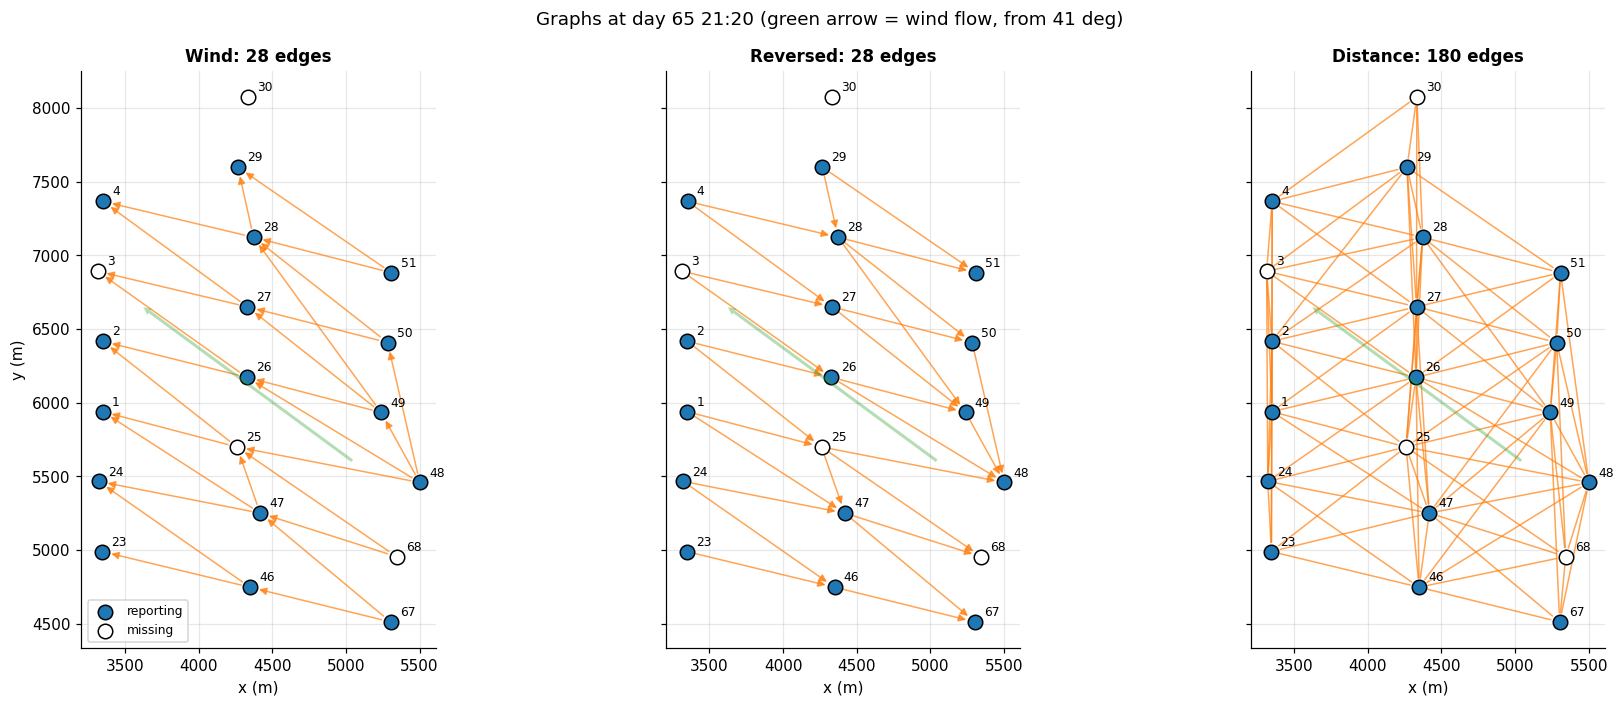

In [27]:
t0_ev = event["step_start"]
fig, axes = plt.subplots(1, 3, figsize=(17, 6.5), sharey=True)
for ax, (name, A) in zip(axes, GRAPHS.items()):
    Ad = A[t0_ev]
    for a, b in zip(*np.nonzero(Ad)):
        if name == "Distance" and a > b:
            continue   # draw each undirected pair once
        ax.annotate("", xy=turb_xy[b], xytext=turb_xy[a],
                    arrowprops=dict(arrowstyle="-" if name == "Distance" else "-|>", color="tab:orange",
                                    lw=1, alpha=0.7, shrinkA=6, shrinkB=6))
    vis0 = ev_visible[0]
    ax.scatter(*turb_xy[vis0].T, s=90, color="tab:blue", edgecolor="black", zorder=3, label="reporting")
    ax.scatter(*turb_xy[~vis0].T, s=90, color="white", edgecolor="black", zorder=3, label="missing")
    for k, tid in enumerate(W.columns):
        ax.annotate(str(tid), turb_xy[k], xytext=(6, 4), textcoords="offset points", fontsize=8)
    # wind arrow (flow direction in plot coordinates)
    c = turb_xy.mean(axis=0)
    ax.annotate("", xy=c + 900 * flow[t0_ev], xytext=c - 900 * flow[t0_ev],
                arrowprops=dict(arrowstyle="simple", color="tab:green", alpha=0.35, lw=0))
    ax.set_title(f"{name}: {int(Ad.sum())} edges")
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("y (m)")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle(f"Graphs at day {event['Day']} {event['start']} (green arrow = wind flow, from {wind_from[t0_ev]:.0f} deg)")
plt.tight_layout()
plt.show()

### 7.3 Turning a batch of snapshots into one graph, and the model

**What, batching:** PyTorch Geometric trains on one big graph made of many small ones. For a batch of 256 snapshots, turbine *k* of snapshot *b* becomes node `b × 20 + k`, and each snapshot's edges are copied over with that numbering. `make_graph_batch` does this for the whole batch at once, and also:
- **Fallback:** adds the fallback edge for every missing turbine with no reporting in-neighbour.
- **Edge features:** attaches 4 numbers to each edge: distance (km), offset x and y (km), and a fallback flag. These are pure geometry and identical across the three graphs, so the only difference between the models remains *which* edges exist.

**What, model:** the same layout as the Transformer in Section 6, so the comparison is fair:
- **Embedding:** the input embedding plus turbine embedding plus position.
- **3 blocks**, each a GATv2 graph-attention layer (4 heads) followed by a feed-forward layer, with residual connections and normalisation.
- **Read-out:** wind speed and power for every turbine.

GATv2 adds a **self-loop** to every node, so a turbine also keeps its own information.

In [28]:
from torch_geometric.nn import GATv2Conv

edge_geom = np.stack([pair_dist, offset[..., 0], offset[..., 1]], axis=-1).astype(np.float32) / 1000.0  # km

def make_graph_batch(A, vis):
    """A: (B, 20, 20) bool, a -> b edges; vis: (B, 20) reporting flags.
    Returns edge_index, edge_attr and the (B, 20) mask of missing turbines that needed a fallback edge."""
    A = np.array(A, copy=True)
    has_reporting_in = (A & vis[:, :, None]).any(axis=1)
    needs_fallback = ~vis & ~has_reporting_in
    nearest = np.where(vis[:, :, None], pair_dist[None], np.inf).argmin(axis=1)   # nearest reporting turbine
    b, k = np.nonzero(needs_fallback)
    A[b, nearest[b, k], k] = True
    is_fb = np.zeros_like(A)
    is_fb[b, nearest[b, k], k] = True

    bb, src, dst = np.nonzero(A)
    edge_index = torch.tensor(np.stack([bb * n_turb + src, bb * n_turb + dst]), device=DEVICE)
    edge_attr = torch.tensor(np.concatenate([edge_geom[src, dst], is_fb[bb, src, dst][:, None]], axis=1),
                             dtype=torch.float32, device=DEVICE)
    return edge_index, edge_attr, needs_fallback


class GraphBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.conv = GATv2Conv(d_model, d_model // n_heads, heads=n_heads, edge_dim=4, dropout=dropout)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))
        self.drop = nn.Dropout(dropout)

    def forward(self, h, edge_index, edge_attr):
        h = h + self.drop(self.conv(self.norm1(h), edge_index, edge_attr))
        return h + self.drop(self.ff(self.norm2(h)))


class WindGAT(nn.Module):
    def __init__(self, turb_xy_km, d_model=64, n_heads=4, n_layers=3, d_ff=128, dropout=0.1):
        super().__init__()
        self.embed_input = nn.Linear(3, d_model)
        self.embed_turbine = nn.Embedding(len(turb_xy_km), d_model)
        self.embed_position = nn.Linear(2, d_model)
        self.register_buffer("xy", torch.tensor(turb_xy_km, dtype=torch.float32))
        self.blocks = nn.ModuleList(GraphBlock(d_model, n_heads, d_ff, dropout) for _ in range(n_layers))
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, 2)

    def forward(self, tokens, edge_index, edge_attr):
        B = tokens.shape[0]
        h = self.embed_input(tokens) + self.embed_turbine.weight + self.embed_position(self.xy)
        h = h.reshape(B * n_turb, -1)                       # one big graph
        for block in self.blocks:
            h = block(h, edge_index, edge_attr)
        return self.head(self.norm(h)).reshape(B, n_turb, 2)


print(f"parameters: {sum(t.numel() for t in WindGAT(turb_xy_km).parameters()):,}")

parameters: 78,594


### 7.4 Train one GNN per graph

**What:** train three GNNs, one per graph, on the same training examples and the same 10% hold-out as the Transformer:
- **Training:** batch size 256, AdamW at learning rate 1e-3.
- **Loss:** error on hidden turbines only.
- **Graph per example:** each example uses the graph for **its own time step's** wind direction.

**Why identical settings:** any difference in accuracy between the three GNNs then comes from the graph alone.

**Training is capped at 10 epochs** (the Transformer was allowed 20), stopping early after 3 epochs without improvement. Graph attention in PyTorch Geometric is slow on a CPU: ~1 min per epoch on the Wind/Reversed graphs and ~2 min on the Distance graph, which has 4–5× more edges. A first attempt at 20 epochs did not finish within 3 hours. The cap is the same for all three GNNs, so the hypothesis test stays fair. Against the Transformer, the GNNs have had less training, so a gap there may partly reflect that.

**Saved models:** each trained GNN is saved to `data/interim/ed_gnn_<graph>.pt` as soon as it finishes, and later runs load it in seconds. Set `RETRAIN_GNN = True` to train from scratch (~45–60 min for all three). Progress is written to `data/interim/ed_gnn_training.log` while training runs.

Wind      loaded from ../data/interim/ed_gnn_wind.pt (trained in 1045 s, 10 epochs)
Reversed  loaded from ../data/interim/ed_gnn_reversed.pt (trained in 1212 s, 10 epochs)
Distance  loaded from ../data/interim/ed_gnn_distance.pt (trained in 1537 s, 10 epochs)


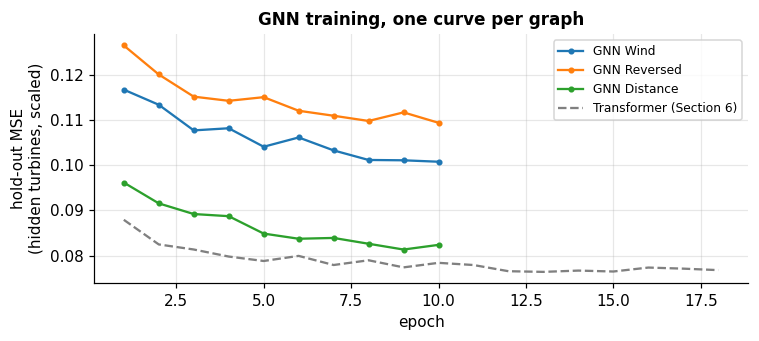

In [29]:
GNN_MAX_EPOCHS, GNN_PATIENCE = 10, 3
RETRAIN_GNN = False
MODEL_DIR = Path("../data/interim")
LOG_PATH = MODEL_DIR / "ed_gnn_training.log"

def log(msg):
    with open(LOG_PATH, "a") as fh:
        fh.write(f"{time.strftime('%H:%M:%S')} {msg}\n")

def train_gnn(name, A_steps, seed=0):
    torch.manual_seed(seed)
    model = WindGAT(turb_xy_km).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    A_rows = A_steps[rows]                       # graph for each training example's own time step

    def loss_on(idx):
        idx = idx.numpy()
        ei, ea, _ = make_graph_batch(A_rows[idx], visible[idx])
        return hidden_mse(model(X_tok[idx], ei, ea), Y_tok[idx], X_tok[idx])

    hist_loss, best, best_state, bad = [], float("inf"), None, 0
    for epoch in range(GNN_MAX_EPOCHS):
        model.train()
        shuffled = fit_idx[torch.randperm(len(fit_idx))]
        for i in range(0, len(shuffled), BATCH):
            opt.zero_grad()
            loss_on(shuffled[i : i + BATCH]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            hold = np.mean([loss_on(hold_idx[i : i + 4096]).item() for i in range(0, len(hold_idx), 4096)])
        hist_loss.append(hold)
        log(f"{name}: epoch {epoch + 1}/{GNN_MAX_EPOCHS}, hold-out MSE {hold:.4f}")
        if hold < best - 1e-4:
            best, bad, best_state = hold, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= GNN_PATIENCE:
                break
    model.load_state_dict(best_state)
    model.eval()
    return model, hist_loss


gnns, gnn_hist = {}, {}
for name, A in GRAPHS.items():
    path = MODEL_DIR / f"ed_gnn_{name.lower()}.pt"
    if path.exists() and not RETRAIN_GNN:
        ckpt = torch.load(path, map_location=DEVICE)   # works for CPU- and GPU-trained files
        gnns[name] = WindGAT(turb_xy_km).to(DEVICE)
        gnns[name].load_state_dict(ckpt["state"])
        gnns[name].eval()
        gnn_hist[name] = ckpt["history"]
        print(f"{name:9s} loaded from {path} (trained in {ckpt['train_seconds']:.0f} s, {len(ckpt['history'])} epochs)")
        continue
    t0 = time.time()
    log(f"{name}: training started")
    gnns[name], gnn_hist[name] = train_gnn(name, A)
    secs = time.time() - t0
    torch.save({"state": gnns[name].state_dict(), "history": [float(h) for h in gnn_hist[name]],
                "train_seconds": float(secs)}, path)
    log(f"{name}: done in {secs:.0f} s, saved to {path}")
    print(f"{name:9s} trained in {secs:5.0f} s, {len(gnn_hist[name])} epochs, "
          f"best hold-out MSE = {min(gnn_hist[name]):.4f}; saved to {path}")

fig, ax = plt.subplots(figsize=(7, 3.2))
for name, h in gnn_hist.items():
    ax.plot(range(1, len(h) + 1), h, "o-", ms=3, label=f"GNN {name}")
ax.plot(range(1, len(history) + 1), history, "--", color="grey", label="Transformer (Section 6)")
ax.set_xlabel("epoch")
ax.set_ylabel("hold-out MSE\n(hidden turbines, scaled)")
ax.set_title("GNN training, one curve per graph")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.5 Test: replay the day-65 outage

**What:** the same replay as 5.4 and 6.4, using the same windows, outage pattern and metric. Each window uses the graphs for its **own** wind direction. Two tables:

1. **By phase:** all methods side by side (patch mean, last known value, MLP, Transformer, 3 GNNs).
2. **By upwind information:** hidden values are split into those with **at least one reporting upwind neighbour** in the *Wind* graph, and those **without** (where the Wind GNN had to use the fallback). All models are scored on exactly the same values in each group.

**Why table 2:** it is the cleanest test of the hypothesis. On the first group, the Wind GNN genuinely uses upwind information, so if upwind relationships help, the gap should show there. The share of hidden values that needed a fallback is printed too.

In [ ]:
def fill_gnn(model, A, ws, ps, vis):
    ei, ea, fb = make_graph_batch(A, vis)
    with torch.no_grad():
        out = model(torch.tensor(make_tokens(ws, ps, vis), device=DEVICE), ei, ea).cpu().numpy()
    return out[..., 0] * w_sd + w_mu, out[..., 1] * p_sd + p_mu, fb

METHODS = ["patch mean", "last known value", "MLP", "Transformer"] + [f"GNN {g}" for g in GRAPHS]
err_rows, fb_count = [], {g: 0 for g in GRAPHS}
n_hidden_total = 0
for split, lo, hi in [("val", 172, 196), ("test", 197, 245)]:
    starts = [s for s in range(1, len(w) - EV_LEN)
              if lo <= step_day[s] <= hi and complete[s - 1 : s + EV_LEN].all()][::EV_LEN]
    for s in starts:
        sl = slice(s, s + EV_LEN)
        ws, ps = w[sl], p[sl]
        fills = {
            "patch mean": (fill_patch_mean(ws, ev_visible), fill_patch_mean(ps, ev_visible)),
            "last known value": (fill_last_known(ws, ev_visible, w[s - 1]), fill_last_known(ps, ev_visible, p[s - 1])),
            "MLP": fill_mlp(ws, ps, ev_visible),
            "Transformer": fill_transformer(ws, ps, ev_visible),
        }
        for g, A in GRAPHS.items():
            fw, fp, fb = fill_gnn(gnns[g], A[sl], ws, ps, ev_visible)
            fills[f"GNN {g}"] = (fw, fp)
            if split == "test":
                fb_count[g] += fb.sum()
        if split == "test":
            n_hidden_total += ev_hidden.sum()

        # hidden values that have a reporting upwind neighbour in the Wind graph
        upwind_info = (A_wind[sl] & ev_visible[:, :, None]).any(axis=1) & ev_hidden
        phase_of = np.where(severe[:, None], "severe", "partial").repeat(n_turb, axis=1)
        for m in METHODS:
            fw, fp = fills[m]
            err_rows.append(pd.DataFrame({
                "split": split, "method": m,
                "phase": phase_of[ev_hidden],
                "upwind_info": upwind_info[ev_hidden],
                "w_err": np.abs(fw - ws)[ev_hidden],
                "p_err": np.abs(fp - ps)[ev_hidden],
            }))

errs = pd.concat(err_rows, ignore_index=True)

def mae_table(df, group, order):
    """MAE over hidden values: rows = (group, method), columns = (metric, split)."""
    g = df.groupby([group, "method", "split"])
    t = pd.concat({"Wspd MAE (m/s)": g["w_err"].mean().round(3).unstack("split"),
                   "Patv MAE (kW)": g["p_err"].mean().round(1).unstack("split")}, axis=1)
    return t.reindex(pd.MultiIndex.from_product([order, METHODS], names=[group, "method"]))

print("share of hidden test values that needed a fallback edge:")
for g in GRAPHS:
    print(f"  {g:9s} {fb_count[g] / n_hidden_total:.0%}")

by_phase = mae_table(pd.concat([errs, errs.assign(phase="all")]), "phase", ["partial", "severe", "all"])
by_phase

In [ ]:
INFO_LABELS = {True: "has reporting upwind neighbour", False: "no reporting upwind neighbour"}
by_info = mae_table(errs.assign(upwind_info=errs["upwind_info"].map(INFO_LABELS)), "upwind_info",
                    list(INFO_LABELS.values()))
counts = errs[(errs.method == "MLP")].groupby(["upwind_info", "split"]).size().unstack()
print("number of hidden values per group:")
print(counts.rename(index={True: "  with upwind info", False: "  without"}).to_string())
by_info

### 7.6 Fill the real day-65 gaps with each GNN

**What:** fill the real event with the three GNNs and plot them next to the Transformer, for the same turbines as before.

**Why:** a visual check that the GNN fills are plausible, and how much the choice of graph changes them. The Wind-GNN version is saved alongside the earlier ones.

In [ ]:
ev_fills = {g: fill_gnn(gnns[g], A[ev_steps], w[ev_steps], p[ev_steps], ev_visible) for g, A in GRAPHS.items()}

gw, gp, _ = ev_fills["Wind"]
event_filled_gnn = event_filled.copy()
event_filled_gnn["Wspd"] = np.where(ev_visible, w[ev_steps], gw).ravel()
event_filled_gnn["Patv"] = np.where(ev_visible, p[ev_steps], gp).ravel()
FILLED_GNN_PATH = Path(f"../data/interim/event_day{event['Day']}_filled_gnn_wind.csv")
event_filled_gnn.to_csv(FILLED_GNN_PATH, index=False)
print(f"saved to {FILLED_GNN_PATH}")

styles = {"Transformer": ("D", "tab:green"), "Wind": ("^", "tab:orange"),
          "Reversed": ("v", "tab:purple"), "Distance": ("s", "tab:brown")}
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True, sharey="row")
for col, tid in enumerate([3, 47]):
    j = W.columns.get_loc(tid)
    hid = ev_hidden[:, j]
    x_ev = (ev_steps - event["step_start"])[hid]
    for row, (obs, k_idx, label) in enumerate([(w, 0, "Wspd (m/s)"), (p, 1, "Patv (kW)")]):
        ax = axes[row, col]
        ax.plot(hist - event["step_start"], obs[hist, j], "o-", ms=3, color="tab:blue", label="reported")
        series = {"Transformer": (tf_w, tf_p)} | {g: ev_fills[g][:2] for g in GRAPHS}
        for name, vals in series.items():
            mk, colr = styles[name]
            ax.plot(x_ev, vals[k_idx][hid, j], mk, ms=6, color=colr, alpha=0.85,
                    label=name if name == "Transformer" else f"GNN {name}")
        ax.axvspan(-0.5, EV_LEN - 0.5, color="grey", alpha=0.12)
        ax.set_ylabel(label if col == 0 else "")
        if row == 0:
            ax.set_title(f"turbine {tid} (missing {hid.sum()}/{EV_LEN} steps)")
        else:
            ax.set_xlabel("steps from event start (10 min)")
        ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Day {event['Day']}: GNN fills by graph vs Transformer (grey band = event)")
plt.tight_layout()
plt.show()

### 7.7 Takeaways

**The hypothesis is not supported.** Of the two conditions, only the first partly holds: *Wind* beats *Reversed* on power, but *Wind* is clearly worse than *Distance*.

| Test windows, all phases | Wind speed MAE (m/s) | Power MAE (kW) |
|---|---|---|
| Transformer | **0.529** | **68.7** |
| GNN Distance | 0.549 | 72.6 |
| MLP | 0.562 | 79.4 |
| GNN Wind | 0.603 | 81.7 |
| patch mean | 0.594 | 81.9 |
| GNN Reversed | 0.598 | 89.2 |

- **The wind direction matters a little, for power only.** *Wind* beats *Reversed* on power (81.7 vs 89.2 kW on test), but the two are level on wind speed. This weakly favours the 275° farm orientation over the 95° alternative from notebook 02.
- **Restricting to upwind turbines hurts much more than it helps.** *Wind* is no better than the patch mean overall (81.7 vs 81.9 kW), while *Distance* is the second-best method after the Transformer.
- **Why: too few edges.** On the wind graph a turbine has on average 2 in-neighbours, and 30% of turbines have none at any given step. During outages it is worse: **66% of hidden test values had no reporting upwind neighbour** and relied on the fallback edge (17% on *Distance*).
- **Even with an upwind neighbour reporting, *Wind* loses:** 72.6 kW against 60.1 kW for the patch mean and 60.4 kW for *Distance*. One or two upwind turbines are a narrower view than the whole neighbourhood, and the wake signal they carry is weak (notebook 02).
- **More neighbours is better.** *Distance* (9 in-neighbours) beats the MLP everywhere and matches the Transformer on wind speed in the partial phase (0.435 m/s for both). The Transformer, which can listen to every reporting turbine, stays best on power.

**Limitations:**
- The GNNs were capped at 10 epochs (the Transformer had up to 20), and *Distance* was still improving, so its gap to the Transformer may partly be under-training.
- One cone (±45°) and one radius (1500 m) were tested. A wider cone or radius gives more upwind neighbours and may behave differently.
- The hold-out scores come from one training run per graph (seed 0); small differences, such as *Wind* vs *Reversed* on wind speed, may be noise.

**Possible next steps:** a looser wind graph (wider cone / radius), or the wind direction as an **edge feature** on the *Distance* graph, so the model can learn how much to trust upwind neighbours instead of being forbidden to listen to the others.